## 1. Імпорт бібліотек

In [53]:
import os, re, time, hashlib, unicodedata, warnings, textwrap, datetime
from importlib.metadata import version
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import requests
import json
import easyocr
from paddleocr import PaddleOCR
from datasets import load_dataset, Image as HFImage
from PIL import Image, ImageDraw, ImageFont, ExifTags, ImageOps
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr
from pillow_heif import register_heif_opener
register_heif_opener()

warnings.filterwarnings("ignore")

## 2. Персональні параметри та налаштування

In [4]:
STUDENT = "Твердун Т.А."
VARIANT = 11
STUDENT_ID = 44
SEED = 1000 * VARIANT + STUDENT_ID
rng = np.random.default_rng(SEED)

FONTS = [
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/times.ttf",
    "C:/Windows/Fonts/calibri.ttf",
    "C:/Windows/Fonts/georgia.ttf",
    "C:/Windows/Fonts/verdana.ttf",
    "C:/Windows/Fonts/tahoma.ttf",
]

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print("SEED =", SEED)

SEED = 11044


## 3. Синтетичний набір даних

### 3.1. Завантаження тексту твору

In [5]:
resp = requests.get(
    "https://uk.wikisource.org/w/index.php",
    params={"title": "Лісова пісня", "action": "raw"},
    headers={"User-Agent": "lab3-ocr-student"},
    timeout=30,
)
resp.raise_for_status()
raw = resp.text

print("Characters loaded:", len(raw))
print(raw[:1500])

Characters loaded: 88563
{{заголовок
 | назва      = Лісова пісня
 | автор      = Леся Українка
 | перекладач = 
 | секція     = 
 | попередня  = 
 | наступна   = 
 | рік        =1911 
 | примітки   = 
}}
<poem>
ЛІСОВА ПІСНЯ
Драма-феєрія в 3-х діях
 
СПИС ДІЯЧІВ "ЛІСОВОЇ ПІСНІ"
 
ПРОЛОГ
 
"Той, що греблі рве". 	Русалка. 
Потерчата (двоє).	        Водяник.
 
ДІЯ І
 
Дядько Лев. 	      Перелесник. 
Лукаш. 	              Пропасниця (без мови). 
Русалка. 	              Потерчата. 
Лісовик. 	              Куць.
Мавка.
 
ДІЯ II
 
Мати Лукашева.	Килина.
Лукаш.	                 Русалка.
Дядько Лев.                "Той, що в скалі
Мавка.                        сидить".
Русалка Польова.     Перелесник.
 
ДІЯ III
 
Мавка.                            Хлопчик.
Лісовик.                          Лукаш.
Куць.                               Діти Килинині
Злидні.                            (без мови).
Мати Лукашева.             Доля.
Килина.                           Перелесник.
 
ПРОЛОГ
 
Старезний, густ

### 3.2. Очищення тексту

In [6]:
text = raw.split("<poem>")[1].split("</poem>")[0]
text = text[text.index("Старезний"):]

def is_speaker(line):
    words = re.sub(r"[^\w\s]", "", line).split()
    singles = sum(len(w) == 1 for w in words)
    return singles >= 3 and all(len(w) <= 2 for w in words)

kept = [l for l in text.splitlines() if not is_speaker(l) and not l.strip().isupper()]
text = " ".join(kept)
text = re.sub(r"\([^)]*\)", " ", text)
text = " ".join(text.split())

print("Characters after cleaning:", len(text))
print(text[:800])

Characters after cleaning: 68044
Старезний, густий, предковічний ліс на Волині. Посеред лісу простора галява з плакучою березою і з великим прастарим дубом. Галява скраю переходить в куп'я та очерети, а в одному місці в яро-зелену драговину - то береги лісового озера, що утворилося з лісового струмка. Струмок той вибігає з гущавини лісу, впадає в озеро, потім, по другім боці озера, знов витікає і губиться в хащах. Саме озеро - тиховоде, вкрите ряскою та лататтям, але з чистим плесом посередині. Містина вся дика, таємнича, але не понура, - повна ніжної, задумливої поліської краси. Провесна. По узліссі і на галяві зеленіє перший ряст і цвітуть проліски та сон-трава. Дерева ще безлисті, але вкриті бростю, що от-от має розкритись. На озері туман то лежить пеленою, то хвилює од вітру, то розривається, одкриваючи блідо-блакитну


### 3.3. Поділ на речення

In [7]:
sentences = re.split(r'(?<=[.!?…])\s+|(?<=[.!?…]")\s+', text)
sentences = [s.lstrip(" ,;:-") for s in sentences]
corpus = list(dict.fromkeys(s for s in sentences if 20 <= len(s) <= 70))

with open("corpus.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(corpus))

print("Sentences total:", len(sentences))
print("Sentences in corpus (20-70 chars):", len(corpus))
for s in corpus[:10]:
    print(s)

Sentences total: 1783
Sentences in corpus (20-70 chars): 803
Старезний, густий, предковічний ліс на Волині.
Дерева ще безлисті, але вкриті бростю, що от-от має розкритись.
З гір на долину біжу, стрибаю, рину!
Чого ти тута блудиш?
Чого зо сну нас будиш?
Чого ж ти тут шугаєш?
Зіб'ю всю вашу воду, таки знайду ту вроду!
Печера в нас маленька, що збудувала ненька.
Убога наша хатка, бо в нас немає татка...
Нехай до мене зрине!


### 3.4. Вибір 40 речень

In [8]:
N_LINES = 40
lines = [str(s) for s in rng.choice(corpus, size=N_LINES, replace=False)]

print("Selected lines:", len(lines))
for s in lines:
    print(s)

Selected lines: 40
Який-бо ти, дідусю, став суворий!
Прохолодитись треба.
Хай Змія-цариця мене скарає, якщо се неправда!
Вже й сон-трава перецвітати стала.
Я ледь що вибрався живий на берег, і рибу розгубив...
Самій увечері в сій пущі сумно.
Мені здається, що жила я завжди...
В очеретах заблимали два бродячі вогники.
Я міркував би, що вже б тобі не тра верби на зиму.
Ти б іще зібрав сюди усіх відьом із лісу.
Якби ж воно такеє говорило, що тямить, ну, то й слухав би, а то...
Ви ж про Царівну мали.
Я не маю сили покинути її...
Чи бач, як знітилась невірна пара, відьомський накоренок!
Ні, се так добре - умерти, як летюча зірка...
"Той, що в скалі сидить" виходить і подається до Мавки.
бач, вона така суха, і все рипить, все згадує про зиму...
Перелесник здригнувся, прудким рухом кинувся геть і зник у лісі.
Вже з вирію поприлітали гості.
Ну, я піду - управлюся тим часом з дробиною.
Відай, ви, дядьку, щось тут проминули.
Чи у людей паруються надовго?
Дяка щирая тобі, ніченько-чарівниченько, 

### 3.5. Малювання рядка тексту

Image shape (height, width): (54, 528)


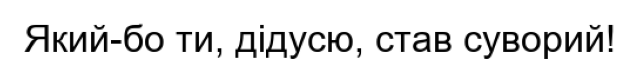

In [9]:
def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

example = render_line(lines[0], FONTS[0])
print("Image shape (height, width):", example.shape)

plt.figure(figsize=(8, 1))
plt.imshow(example, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### 3.6. Нерівне освітлення

level  0 %: right edge background = 255
level 15 %: right edge background = 216
level 30 %: right edge background = 178
level 45 %: right edge background = 140
level 60 %: right edge background = 102
level 75 %: right edge background = 63


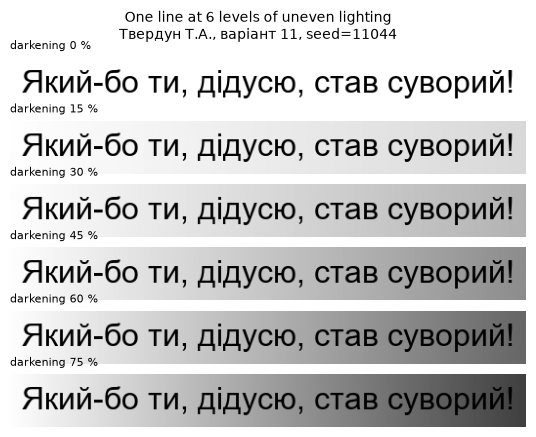

In [10]:
LEVELS = [0, 15, 30, 45, 60, 75]

def degrade(img, level):
    h, w = img.shape
    light = np.linspace(1.0, 1.0 - level / 100, w)
    out = img.astype(np.float32) * light
    return np.clip(out, 0, 255).astype(np.uint8)

for lvl in LEVELS:
    print(f"level {lvl:2d} %: right edge background = {degrade(example, lvl)[0, -1]}")

fig, axes = plt.subplots(len(LEVELS), 1, figsize=(8, 0.8 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    ax.imshow(degrade(example, lvl), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"darkening {lvl} %", fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"One line at {len(LEVELS)} levels of uneven lighting\n"
             f"{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.7. Генерація набору

In [11]:
FACTOR = "light"

records = []
for i, sentence in enumerate(lines):
    font = FONTS[i % len(FONTS)]
    size = int(rng.integers(22, 36))
    clean = render_line(sentence, font, size=size)
    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, lvl))
        records.append({"id": i, "level": lvl, "path": path, "gt": sentence,
                        "font": os.path.basename(font), "size": size})

ds = pd.DataFrame(records)
print("Images saved:", len(ds))
ds.head(8)

Images saved: 240


,id,level,path,gt,font,size
0,0,0,data/000_light_0.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
1,0,15,data/000_light_15.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
2,0,30,data/000_light_30.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
3,0,45,data/000_light_45.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
4,0,60,data/000_light_60.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
5,0,75,data/000_light_75.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
6,1,0,data/001_light_0.png,Прохолодитись треба.,times.ttf,26
7,1,15,data/001_light_15.png,Прохолодитись треба.,times.ttf,26


### 3.8. Еталон і хеш SHA-256

In [12]:
ds.to_csv("data/ground_truth.csv", index=False, lineterminator="\n")

with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()

print("Ground truth rows:", len(ds))
print("SHA-256:", sha)

Ground truth rows: 240
SHA-256: bb4adf6309f3819522854306055ef5b6cb151dd4dcf21b89cf1da4d77c08c667


## 4. Відкритий набір CORD v2

### 4.1. Завантаження чеків

[2026-11-09 16:05:58,090] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/datasets/naver-clova-ix/cord-v2/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"
[2026-11-09 16:05:58,129] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/naver-clova-ix/cord-v2/7f0115a4b758a71d6473b8d085751692da2fef98/README.md?%2Fdatasets%2Fnaver-clova-ix%2Fcord-v2%2Fresolve%2Fmain%2FREADME.md=&etag=%22b187bb7e7d837a367ccd0862441947ad412c77f7%22 "HTTP/1.1 200 OK"
[2026-11-09 16:05:58,257] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/datasets/naver-clova-ix/cord-v2/resolve/7f0115a4b758a71d6473b8d085751692da2fef98/cord-v2.py "HTTP/1.1 404 Not Found"
[2026-11-09 16:05:59,422] [    INFO] _client.py:1084 - HTTP Request: HEAD https://s3.amazonaws.com/datasets.huggingface.co/datasets/datasets/naver-clova-ix/cord-v2/naver-clova-ix/cord-v2.py "HTTP/1.1 404 Not Found"
[2026-11-09 16:05:59,867] [    INFO] _client.py:

Dataset({
    features: ['image', 'ground_truth'],
    num_rows: 100
})
Receipt 0 size (width, height): (432, 648)


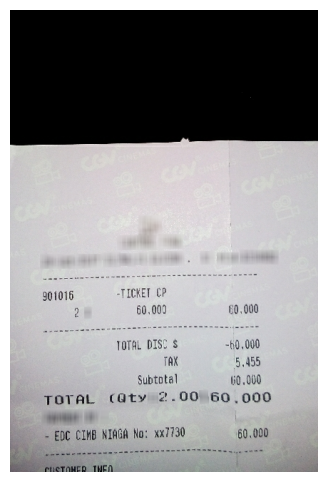

In [13]:
cord = load_dataset(
    "naver-clova-ix/cord-v2",
    data_files={"test": "data/test-*.parquet"},
    split="test",
)
cord = cord.cast_column("image", HFImage())
print(cord)

receipt = cord[0]["image"]
print("Receipt 0 size (width, height):", receipt.size)

plt.figure(figsize=(4, 6))
plt.imshow(receipt)
plt.axis("off")
plt.show()

### 4.2. Розмітка чека

In [14]:
gt = json.loads(cord[0]["ground_truth"])
print("Keys:", list(gt.keys()))
print("Annotated lines:", len(gt["valid_line"]))

for j, line in enumerate(gt["valid_line"]):
    line_text = " ".join(w["text"] for w in line["words"])
    print(j, line["category"], "|", line_text)

print(gt["valid_line"][1]["words"][0])

Keys: ['gt_parse', 'meta', 'valid_line', 'roi', 'repeating_symbol', 'dontcare']
Annotated lines: 11
0 menu.num | 901016
1 menu.nm | -TICKET CP
2 menu.cnt | 2
3 menu.price | 60.000
4 menu.itemsubtotal | 60.000
5 sub_total.discount_price | TOTAL DISC $ -60.000
6 sub_total.tax_price | TAX 5.455
7 sub_total.subtotal_price | Subtotal 60.000
8 total.total_price | TOTAL 60.000
9 total.menuqty_cnt | (Qty 2.00
10 total.creditcardprice | EDC CIMB NIAGA No: xx7730 60.000
{'quad': {'x2': 200, 'y3': 406, 'x3': 200, 'y4': 406, 'x1': 146, 'y1': 386, 'x4': 146, 'y2': 386}, 'is_key': 0, 'row_id': 2028655, 'text': '-TICKET'}


### 4.3. Поділ рядків на фрагменти

In [15]:
def word_box(word):
    q = word["quad"]
    xs = [q["x1"], q["x2"], q["x3"], q["x4"]]
    ys = [q["y1"], q["y2"], q["y3"], q["y4"]]
    return min(xs), min(ys), max(xs), max(ys)

def split_line(line):
    words = sorted(line["words"], key=lambda w: (w["row_id"], word_box(w)[0]))
    segments = []
    for w in words:
        if segments:
            prev = segments[-1][-1]
            x0, y0, x1, y1 = word_box(prev)
            gap = word_box(w)[0] - x1
            if w["row_id"] == prev["row_id"] and gap < (y1 - y0):
                segments[-1].append(w)
                continue
        segments.append([w])
    return segments

for j, line in enumerate(gt["valid_line"]):
    parts = [" ".join(w["text"] for w in seg) for seg in split_line(line)]
    print(j, parts)

0 ['901016']
1 ['-TICKET CP']
2 ['2']
3 ['60.000']
4 ['60.000']
5 ['TOTAL DISC $', '-60.000']
6 ['TAX', '5.455']
7 ['Subtotal', '60.000']
8 ['TOTAL', '60.000']
9 ['(Qty 2.00']
10 ['EDC CIMB NIAGA No: xx7730', '60.000']


### 4.4. Фрагменти з усіх чеків

In [16]:
fragments = []
for r, gt_json in enumerate(cord["ground_truth"]):
    receipt_gt = json.loads(gt_json)
    for j, line in enumerate(receipt_gt["valid_line"]):
        for k, seg in enumerate(split_line(line)):
            boxes = [word_box(w) for w in seg]
            fragments.append({
                "receipt": r, "line": j, "seg": k,
                "category": line["category"],
                "gt": " ".join(w["text"] for w in seg),
                "x0": min(b[0] for b in boxes), "y0": min(b[1] for b in boxes),
                "x1": max(b[2] for b in boxes), "y1": max(b[3] for b in boxes),
            })

frags = pd.DataFrame(fragments)
print("All fragments:", len(frags))

frags = frags[frags["gt"].str.len() >= 3].reset_index(drop=True)
print("Fragments with 3+ characters:", len(frags))
frags.head()

All fragments: 1732
Fragments with 3+ characters: 1418


,receipt,line,seg,category,gt,x0,y0,x1,y1
0,0,0,0,menu.num,901016,42,392,92,412
1,0,1,0,menu.nm,-TICKET CP,146,386,222,406
2,0,3,0,menu.price,60.000,174,410,224,430
3,0,4,0,menu.itemsubtotal,60.000,304,410,352,430
4,0,5,0,sub_total.discount_price,TOTAL DISC $,146,457,238,480


### 4.5. Вибір і вирізання 150 фрагментів

In [17]:
N_CORD = 150
idx = rng.choice(len(frags), size=N_CORD, replace=False)
sample = frags.iloc[np.sort(idx)].reset_index(drop=True)
sample["path"] = [f"data/cord/{r:03d}_{j:02d}_{k}.png"
                  for r, j, k in zip(sample["receipt"], sample["line"], sample["seg"])]

os.makedirs("data/cord", exist_ok=True)
for r, group in sample.groupby("receipt"):
    photo = cord[int(r)]["image"].convert("L")
    for row in group.itertuples():
        pad = max(2, round(0.1 * (row.y1 - row.y0)))
        crop = photo.crop((max(0, row.x0 - pad), max(0, row.y0 - pad),
                           min(photo.width, row.x1 + pad), min(photo.height, row.y1 + pad)))
        crop.save(row.path)

sample.to_csv("data/cord_ground_truth.csv", index=False, lineterminator="\n")
print("CORD fragments saved:", len(sample))
print("Receipts used:", sample["receipt"].nunique())
sample.head()

CORD fragments saved: 150
Receipts used: 74


,receipt,line,seg,category,gt,x0,y0,x1,y1,path
0,0,6,0,sub_total.tax_price,TAX,212,482,240,502,data/cord/000_06_0.png
1,1,6,1,total.total_price,91000,539,826,813,867,data/cord/001_06_1.png
2,3,6,1,total.total_price,"11,000",584,798,691,842,data/cord/003_06_1.png
3,4,6,0,menu.nm,CHIKEN KATSU FF,102,625,340,666,data/cord/004_06_0.png
4,5,3,0,sub_total.subtotal_price,SUBTTL,691,2009,1092,2077,data/cord/005_03_0.png


### 4.6. Приклади фрагментів

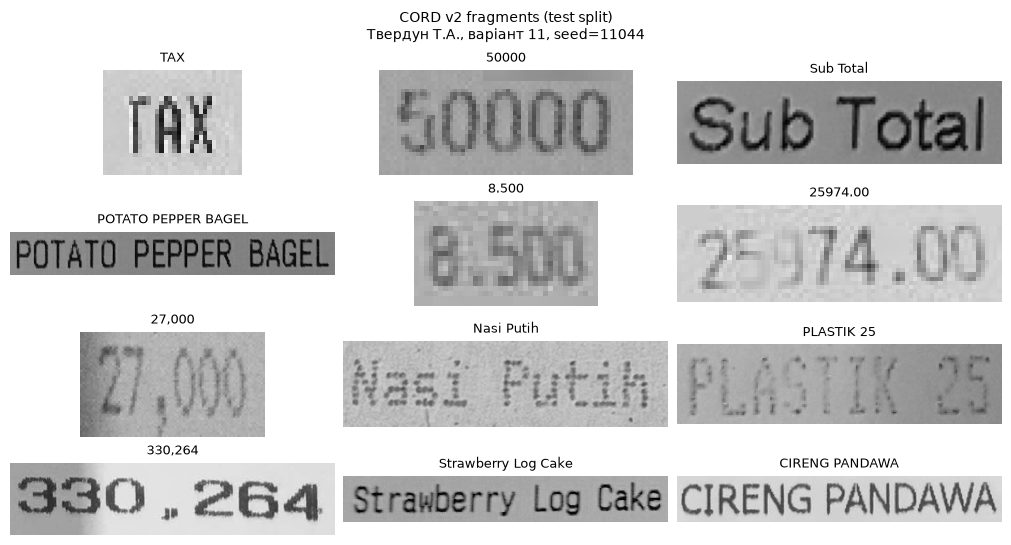

In [18]:
show = sample.iloc[::12].head(12)

fig, axes = plt.subplots(4, 3, figsize=(10, 5.5), layout="constrained")
for ax, row in zip(axes.flat, show.itertuples()):
    img = cv2.imread(row.path, cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(row.gt, fontsize=9)
    ax.axis("off")
fig.suptitle(f"CORD v2 fragments (test split)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig_cord_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Власні дані

### 5.1. Фото, EXIF і транскрипції

In [35]:
OWN = {
    "page_flat": "my_photos/page_flat.heic",
    "page_side": "my_photos/page_side.heic",
    "page_angle": "my_photos/page_angle.heic",
    "receipt1": "my_photos/receipt1.jpg",
    "receipt2": "my_photos/receipt2.jpg",
    "receipt3": "my_photos/receipt3.jpg",
}
ROTATE_180 = {"receipt1"}

def exif_info(path):
    tags = {ExifTags.TAGS.get(k, k): v for k, v in Image.open(path).getexif().items()}
    return tags.get("DateTime"), tags.get("Model")

def load_photo(path, rotate180=False, max_side=2000):
    img = ImageOps.exif_transpose(Image.open(path)).convert("L")
    if rotate180:
        img = img.rotate(180)
    k = max_side / max(img.size)
    img = img.resize((round(img.width * k), round(img.height * k)), Image.LANCZOS)
    return np.array(img)

own_rows = []
own_imgs = {}
for name, path in OWN.items():
    own_imgs[name] = load_photo(path, rotate180=name in ROTATE_180)
    taken, camera = exif_info(path)
    with open(path.rsplit(".", 1)[0] + ".txt", encoding="utf-8") as f:
        gt_text = f.read()
    own_rows.append({"name": name, "file": os.path.basename(path), "taken": taken,
                     "camera": camera, "size": own_imgs[name].shape,
                     "gt_words": len(gt_text.split()), "gt": gt_text})

own = pd.DataFrame(own_rows)
own.drop(columns="gt")

,name,file,taken,camera,size,gt_words
0,page_flat,page_flat.heic,2026:11:09 17:01:35,Galaxy A36 5G,"(2000, 1125)",29
1,page_side,page_side.heic,2026:11:09 17:05:38,Galaxy A36 5G,"(2000, 1125)",29
2,page_angle,page_angle.heic,2026:11:09 17:06:53,Galaxy A36 5G,"(2000, 1125)",29
3,receipt1,receipt1.jpg,2026:11:09 19:13:59,Galaxy A36 5G,"(2000, 1125)",66
4,receipt2,receipt2.jpg,2026:11:09 19:12:23,Galaxy A36 5G,"(2000, 1125)",56
5,receipt3,receipt3.jpg,2026:11:09 19:13:06,Galaxy A36 5G,"(2000, 1125)",52


### 5.2. Огляд фото

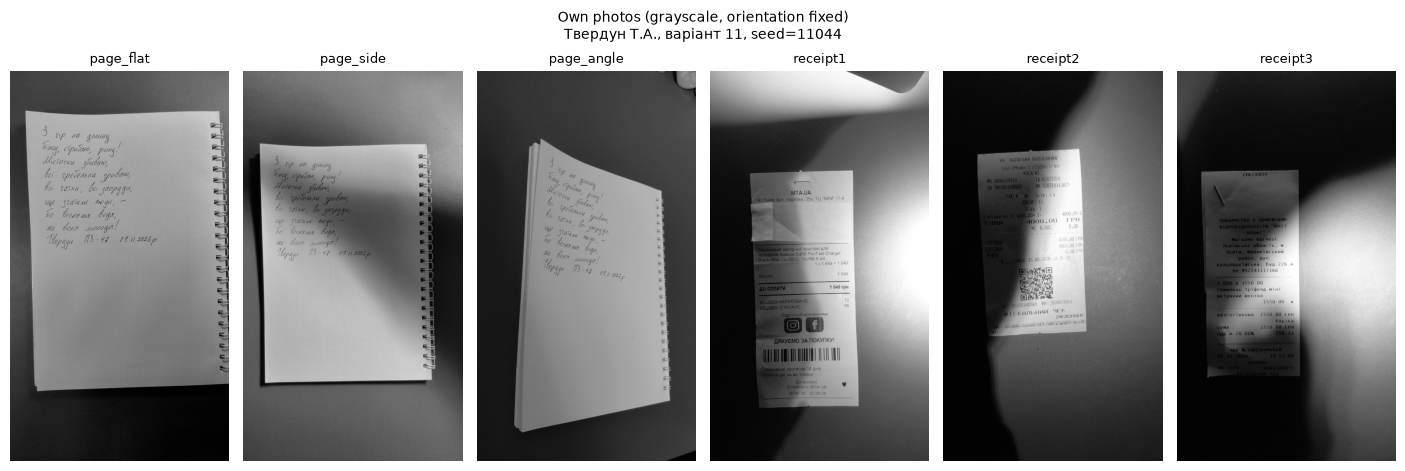

In [36]:
fig, axes = plt.subplots(1, 6, figsize=(14, 4.6), layout="constrained")
for ax, (name, img) in zip(axes, own_imgs.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
fig.suptitle(f"Own photos (grayscale, orientation fixed)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig_own_photos.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Гіпотези

**Г1. Без обробки тінь майже не заважає.** Без попередньої обробки обидва інструменти на синтетичних рядках матимуть CER не більше 5 % без тіні (0 %), а при найсильнішій тіні (75 %) CER виросте не більше ніж на 3 в. п.
*Бо:* навіть у найтемнішому місці фон усе ще помітно світліший за текст, а нейромережі вчилися на фото з нерівним світлом.

**Г2. Оцу не справляється з тінню.** Після бінаризації Оцу CER обох інструментів при тіні 60–75 % буде більше 30 %. Без тіні або зі слабкою тінню (0–15 %) Оцу майже не змінить результат: різниця не більше 1 в. п.
*Бо:* Оцу ставить один поріг на всю картинку, тому затінений фон стає чорним разом із текстом.

**Г3. Адаптивна бінаризація справляється з тінню.** З адаптивною бінаризацією CER на будь-якому рівні тіні буде гіршим, ніж без обробки, не більше ніж на 2 в. п., а при тіні 60–75 % — щонайменше втричі кращим, ніж з Оцу.
*Бо:* адаптивна бінаризація обирає поріг окремо для кожної невеликої ділянки, тож плавна тінь їй не заважає.

**Г4. На справжніх чеках помилок більше.** На фрагментах CORD CER буде у 3–5 разів вищим, ніж на синтетичних рядках без тіні (приблизно 15–25 % проти 3–5 %).
*Бо:* на справжніх фото є розмиття, низька якість, друк з крапок і текстура паперу, а синтетичні рядки ідеально чисті.

**Г5. На власних фото найважчий рукопис.** На фото рукописної сторінки CER обох інструментів буде більше 50 % (найгірше — на фото під кутом). На чеках з тінню CER буде 15–35 %, і адаптивна бінаризація знизить його порівняно з Оцу щонайменше на 10 в. п.
*Бо:* інструменти вчилися на друкованому тексті, а не на рукописі; тінь від руки на чеку — та сама проблема, що й у синтетиці.

**Г6. PaddleOCR кращий на чеках.** На CORD CER PaddleOCR буде нижчим, ніж у EasyOCR, щонайменше на 5 в. п. На українських синтетичних рядках різниця між ними буде меншою за 2 в. п.
*Бо:* PaddleOCR вчили на великій кількості документів і чеків, а чистий друкований рядок обидва інструменти мають читати майже без помилок.

## 7. Попередня обробка

### 7.1. Конфігурації обробки

In [19]:
def preprocess(img, steps=()):
    out = img.copy()
    for step in steps:
        if step == "flatten":
            background = cv2.morphologyEx(out, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
            out = cv2.divide(out, background, scale=255)
        elif step == "clahe":
            out = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(out)
        elif step == "otsu":
            out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
        elif step == "adaptive":
            out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 31, 15)
    return out

PREP = {
    "raw": (),
    "otsu": ("otsu",),
    "adaptive": ("adaptive",),
    "clahe": ("clahe",),
    "flatten": ("flatten",),
    "flatten+otsu": ("flatten", "otsu"),
}
print("Configurations:", list(PREP))

Configurations: ['raw', 'otsu', 'adaptive', 'clahe', 'flatten', 'flatten+otsu']


### 7.2. Приклад обробки рядка з тінню

Otsu threshold at 75 %: 134.0


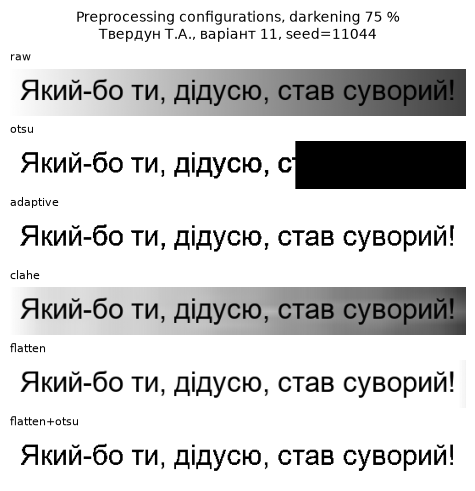

In [20]:
img = cv2.imread(f"data/000_{FACTOR}_75.png", cv2.IMREAD_GRAYSCALE)
print("Otsu threshold at 75 %:", cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0])

fig, axes = plt.subplots(len(PREP), 1, figsize=(8, 0.8 * len(PREP)), layout="constrained")
for ax, (name, steps) in zip(axes, PREP.items()):
    ax.imshow(preprocess(img, steps), cmap="gray", vmin=0, vmax=255)
    ax.set_title(name, fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"Preprocessing configurations, darkening 75 %\n"
             f"{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig_prep_examples.png", dpi=150, bbox_inches="tight")
plt.show()

**Інтерпретація.** На рисунку один синтетичний рядок із найсильнішим затемненням (75 %) після кожної з шести конфігурацій. Глобальна бінаризація Оцу обрала поріг 134: усі пікселі темніші за 134 стають чорними. Оскільки фон праворуч затемнено до ≈ 63, вся права частина рядка перетворилася на суцільний чорний прямокутник разом із текстом. Адаптивна бінаризація, flatten і flatten+otsu ають чистий текст на білому фоні, бо поріг або обчислюється локально, або тінь спершу прибирається діленням на оцінку фону. CLAHE лише посилює локальний контраст.

## 8. Розпізнавання

### 8.1. Ініціалізація інструментів

In [23]:
easy = {
    "uk": easyocr.Reader(["uk", "en"], gpu=False, verbose=False),
    "en": easyocr.Reader(["en"], gpu=False, verbose=False),
}

PADDLE_REC = {"uk": "eslav_PP-OCRv5_mobile_rec", "en": "en_PP-OCRv5_mobile_rec"}
paddle = {
    lang: PaddleOCR(
        text_detection_model_name="PP-OCRv5_mobile_det",
        text_recognition_model_name=rec,
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=False,
        enable_mkldnn=False,
    )
    for lang, rec in PADDLE_REC.items()
}
print("OCR engines ready")

Creating model: ('PP-OCRv5_mobile_det', None)
Using official model (PP-OCRv5_mobile_det), the model files will be automatically downloaded and saved in `C:\Users\Tanya\.paddlex\official_models\PP-OCRv5_mobile_det`.
[2026-11-09 20:11:53,295] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/PaddlePaddle/PP-OCRv5_mobile_det/revision/main "HTTP/1.1 200 OK"
[2026-11-09 20:11:53,447] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/PaddlePaddle/PP-OCRv5_mobile_det/tree/0d63e78e2b680928f6b1747d76a08db6e645efb7?recursive=true&expand=false "HTTP/1.1 200 OK"
Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s][2026-11-09 20:11:53,629] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/PaddlePaddle/PP-OCRv5_mobile_det/resolve/0d63e78e2b680928f6b1747d76a08db6e645efb7/.gitattributes "HTTP/1.1 307 Temporary Redirect"
[2026-11-09 20:11:53,690] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/a

OCR engines ready


### 8.2. Функції розпізнавання

In [24]:
def reading_order(boxes, texts):
    items = []
    for box, t in zip(boxes, texts):
        pts = np.asarray(box, dtype=float)
        items.append((pts[:, 1].mean(), pts[:, 0].min(), pts[:, 1].max() - pts[:, 1].min(), t))
    items.sort()
    rows = []
    for cy, x, h, t in items:
        if rows and abs(cy - rows[-1][0]) < h / 2:
            rows[-1][1].append((x, t))
        else:
            rows.append([cy, [(x, t)]])
    return " ".join(t for _, row in rows for _, t in sorted(row))

def ocr_easyocr(img, lang="uk"):
    t0 = time.perf_counter()
    res = easy[lang].readtext(img, detail=1)
    text = reading_order([r[0] for r in res], [r[1] for r in res])
    conf = float(np.mean([r[2] for r in res])) if res else 0.0
    return text, conf, time.perf_counter() - t0

def ocr_paddle(img, lang="uk"):
    t0 = time.perf_counter()
    res = paddle[lang].predict(cv2.cvtColor(img, cv2.COLOR_GRAY2BGR))[0]
    text = reading_order(res["rec_polys"], res["rec_texts"])
    conf = float(np.mean(res["rec_scores"])) if len(res["rec_texts"]) else 0.0
    return text, conf, time.perf_counter() - t0

ENGINES = {"EasyOCR": ocr_easyocr, "PaddleOCR": ocr_paddle}

### 8.3. Перевірка на одному рядку

In [25]:
for lvl in (0, 75):
    img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
    for prep in ("raw", "otsu", "adaptive"):
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(preprocess(img, PREP[prep]))
            print(f"{lvl:2d}% {prep:8s} {eng:9s} {sec:.2f}s conf={conf:.2f} | {text}")
print("Ground truth:", lines[0])

 0% raw      EasyOCR   0.26s conf=0.63 | Який-бо ти; дідусю; став суворий!
 0% raw      PaddleOCR 0.44s conf=0.97 | Який-бо ти, дідусю, став суворий!
 0% otsu     EasyOCR   0.46s conf=0.72 | Який-бо ти, дідусю, став суворий!
 0% otsu     PaddleOCR 0.33s conf=0.97 | Який-бо ти, дідусю, став суворий!
 0% adaptive EasyOCR   0.52s conf=0.82 | Який-бо ТИ; дідусю; став суворий!
 0% adaptive PaddleOCR 0.32s conf=0.99 | Який-бо ти, дідусю, став суворий!
75% raw      EasyOCR   0.45s conf=0.98 | Який-бо ти; дідусю, став суворий!
75% raw      PaddleOCR 0.30s conf=0.97 | Який-бо ти, дідусю, став суворий!
75% otsu     EasyOCR   0.42s conf=0.83 | Який-бо ТИ, дідусю,
75% otsu     PaddleOCR 0.26s conf=1.00 | Який-бо ти, дідусю, с
75% adaptive EasyOCR   0.50s conf=0.69 | Який-бо ТИ, дідусю; став суворий!
75% adaptive PaddleOCR 0.29s conf=0.99 | Який-бо ти, дідусю, став суворий!
Ground truth: Який-бо ти, дідусю, став суворий!


## 9. Метрики

**Метрики.** Обидві рахуються через відстань Левенштейна — мінімальну кількість замін (S), видалень (D) і вставлень (I), щоб із результату OCR отримати еталон:

- CER = (S + D + I) / N, де N — кількість символів еталону;
- WER — та сама формула для слів (N — кількість слів еталону).

**Правила нормалізації**:

1. Unicode NFC — різні записи тієї самої літери (наприклад, «й» одним символом або «и» + знак) зводяться до одного.
2. Апострофи `’ ʼ ‘ ` ´` замінюються на `'` — інакше «м'ята» і «м’ята» вважалися б різними словами.
3. Будь-які послідовності пробілів, табуляцій і переносів рядка замінюються одним пробілом — транскрипції сторінок і чеків мають переноси, а OCR повертає текст через пробіли.
4. **Регістр і розділові знаки не змінюються.** Обґрунтування: у чеках розділові знаки несуть зміст (сума `1550.00`, дата `04.05.2026`, час `19-51-09`), а регістр важливий у кодах і назвах (`CWQTeeMskeM`, `MTA.UA`).

### 9.1. Нормалізація тексту, CER і WER

In [26]:
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"

def normalize(s):
    s = "" if pd.isna(s) else str(s)
    s = unicodedata.normalize("NFC", s)
    for a in APOSTROPHES:
        s = s.replace(a, "'")
    return re.sub(r"\s+", " ", s).strip()

def cer(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

def wer(gt, pred):
    gt, pred = normalize(gt).split(), normalize(pred).split()
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

print("Example from the guide:", round(cer("інженерія даних", "інженерія даиих"), 3),
      round(wer("інженерія даних", "інженерія даиих"), 3))
print("EasyOCR semicolons:", round(cer(lines[0], "Який-бо ти; дідусю; став суворий!"), 3),
      round(wer(lines[0], "Який-бо ти; дідусю; став суворий!"), 3))
print("Otsu cut-off:", round(cer(lines[0], "Який-бо ТИ, дідусю,"), 3))
print("Empty result:", cer(lines[0], ""))

Example from the guide: 0.067 0.5
EasyOCR semicolons: 0.061 0.4
Otsu cut-off: 0.485
Empty result: 1.0


## 10. Експеримент на синтетичних даних

### 10.1. Розпізнавання всіх конфігурацій

In [27]:
rows = []
t_start = time.perf_counter()
for r in ds.itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    for prep_name, steps in PREP.items():
        prepped = preprocess(img, steps)
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(prepped, "uk")
            rows.append({"id": r.id, "level": r.level, "engine": eng, "prep": prep_name,
                         "gt": r.gt, "pred": text, "conf": conf, "sec": sec})
    if (r.Index + 1) % 24 == 0:
        print(f"{r.Index + 1}/{len(ds)} images, {time.perf_counter() - t_start:.0f} s")

res = pd.DataFrame(rows)
res["cer"] = [cer(g, p) for g, p in zip(res["gt"], res["pred"])]
res["wer"] = [wer(g, p) for g, p in zip(res["gt"], res["pred"])]
res.to_csv("data/results_synth.csv", index=False)
print("Runs:", len(res), "| total time:", round(time.perf_counter() - t_start), "s")

24/240 images, 116 s
48/240 images, 244 s
72/240 images, 396 s
96/240 images, 536 s
120/240 images, 691 s
144/240 images, 834 s
168/240 images, 953 s
192/240 images, 1086 s
216/240 images, 1228 s
240/240 images, 1348 s
Runs: 2880 | total time: 1348 s


### 10.2. Зведена таблиця CER

In [28]:
summary = (res.groupby(["engine", "prep", "level"])["cer"].mean()
           .unstack("level") * 100).round(1)
summary

level                    0    15   30   45    60    75
engine    prep                                        
EasyOCR   adaptive      7.2  6.9  6.9  6.6   6.8   6.9
          clahe         6.2  5.8  5.7  5.3   5.3   5.4
          flatten       6.1  6.0  6.0  6.0   6.0   6.1
          flatten+otsu  7.1  7.2  7.2  7.1   7.1   7.1
          otsu          7.1  7.3  7.1  6.8  36.7  45.1
          raw           6.1  6.1  5.9  5.8   5.7   5.9
PaddleOCR adaptive      1.8  1.8  1.7  1.7   1.6   1.8
          clahe         1.6  1.0  1.1  1.5   1.2   1.4
          flatten       1.6  1.6  1.6  1.5   1.6   1.7
          flatten+otsu  1.9  1.8  1.8  1.8   1.8   1.7
          otsu          1.9  2.0  1.9  1.8  32.0  41.4
          raw           1.6  1.0  1.1  1.4   1.4   1.5

### 10.3. Абляційна діаграма

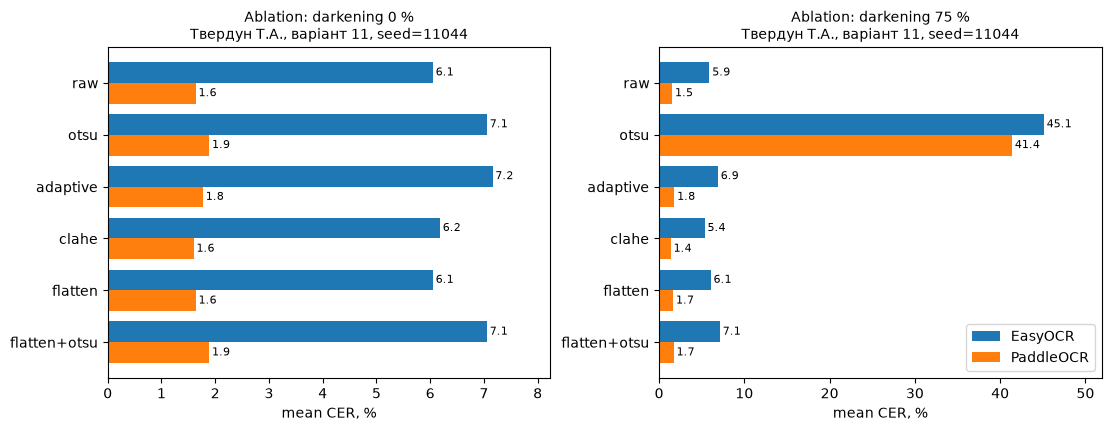

In [29]:
order = list(PREP)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for ax, lvl in zip(axes, (0, 75)):
    sub = (res[res["level"] == lvl].groupby(["prep", "engine"])["cer"].mean()
           .unstack("engine").loc[order] * 100)
    y = np.arange(len(order))
    for k, eng in enumerate(sub.columns):
        bars = ax.barh(y + (k - 0.5) * 0.4, sub[eng], height=0.4, label=eng)
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
    ax.set_yticks(y, order)
    ax.invert_yaxis()
    ax.set_xlabel("mean CER, %")
    ax.margins(x=0.15)
    stamp(ax, f"Ablation: darkening {lvl} %")
axes[1].legend(loc="lower right")
fig.savefig("figures/fig5_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

**Інтерпретація.** Діаграма показує середній CER (по 40 рядках) кожної з шести конфігурацій для обох інструментів без тіні (0 %) і з найсильнішою тінню (75 %); базовий варіант — `raw`.

*Без тіні* обробка майже нічого не змінює: EasyOCR 6,1–7,2 %, PaddleOCR 1,6–1,9 %. Будь-яка бінаризація навіть трохи погіршує результат (EasyOCR: `otsu` 7,1 % і `adaptive` 7,2 % проти 6,1 % без обробки), бо нейромережі навчені на сірих природних зображеннях, а різкі чорно-білі краї для них менш звичні.

*При тіні 75 %* вирішальним стає вибір бінаризації: Оцу дає 45,1 % (EasyOCR) і 41,4 % (PaddleOCR), тобто в 6–28 разів гірше за `raw` (5,9 % і 1,5 %). Адаптивна бінаризація (6,9 % і 1,8 %) і вирівнювання освітлення (`flatten` 6,1 % і 1,7 %) тінь нейтралізують. Комбінація `flatten+otsu` (7,1 % і 1,7 %) показує, що сам Оцу шкідливий, але після вирівнювання освітлення працює нормально. Найкращий результат при сильній тіні дає CLAHE (5,4 % і 1,4 %), але відрив від `raw` (0,5 і 0,1 в. п.) менший за ширину довірчих інтервалів (≈ 3 в. п. для EasyOCR), тож його не можна вважати надійним.

*Висновок:* для синтетичних рядків попередня обробка не потрібна; якщо бінаризація необхідна, використовувати адаптивну або `flatten+otsu`, але не глобальний Оцу. 

*Додатковий експеримент:* перевірити ці ж конфігурації з іншими параметрами (вікно адаптивної бінаризації 15/51, ядро `flatten` 9/25).

## 11. Розпізнавання CORD

### 11.1. Розпізнавання всіх конфігурацій

In [30]:
rows = []
t_start = time.perf_counter()
for r in sample.itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    for prep_name, steps in PREP.items():
        prepped = preprocess(img, steps)
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(prepped, "en")
            rows.append({"receipt": r.receipt, "line": r.line, "seg": r.seg, "category": r.category,
                         "engine": eng, "prep": prep_name, "gt": r.gt, "pred": text,
                         "conf": conf, "sec": sec})
    if (r.Index + 1) % 15 == 0:
        print(f"{r.Index + 1}/{len(sample)} fragments, {time.perf_counter() - t_start:.0f} s")

res_cord = pd.DataFrame(rows)
res_cord["cer"] = [cer(g, p) for g, p in zip(res_cord["gt"], res_cord["pred"])]
res_cord["wer"] = [wer(g, p) for g, p in zip(res_cord["gt"], res_cord["pred"])]
res_cord.to_csv("data/results_cord.csv", index=False)
print("Runs:", len(res_cord), "| total time:", round(time.perf_counter() - t_start), "s")

15/150 fragments, 35 s
30/150 fragments, 73 s
45/150 fragments, 112 s
60/150 fragments, 143 s
75/150 fragments, 181 s
90/150 fragments, 215 s
105/150 fragments, 250 s
120/150 fragments, 291 s
135/150 fragments, 332 s
150/150 fragments, 360 s
Runs: 1800 | total time: 360 s


### 11.2. Зведена таблиця CER

In [31]:
summary_cord = (res_cord.groupby(["engine", "prep"])["cer"].mean()
                .unstack("prep")[list(PREP)] * 100).round(1)
summary_cord

prep,raw,otsu,adaptive,clahe,flatten,flatten+otsu
engine,,,,,,
EasyOCR,26.2,26.2,29.1,25.2,27.8,22.6
PaddleOCR,8.3,13.0,28.5,16.6,10.5,13.8


## 12. Розпізнавання власних фото

### 12.1. Розпізнавання всіх конфігурацій

In [37]:
gt_own = dict(zip(own["name"], own["gt"]))

rows = []
t_start = time.perf_counter()
for name, img in own_imgs.items():
    for prep_name, steps in PREP.items():
        prepped = preprocess(img, steps)
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(prepped, "uk")
            rows.append({"name": name, "engine": eng, "prep": prep_name,
                         "gt": gt_own[name], "pred": text, "conf": conf, "sec": sec})
    print(f"{name} done, {time.perf_counter() - t_start:.0f} s")

res_own = pd.DataFrame(rows)
res_own["cer"] = [cer(g, p) for g, p in zip(res_own["gt"], res_own["pred"])]
res_own["wer"] = [wer(g, p) for g, p in zip(res_own["gt"], res_own["pred"])]
res_own.to_csv("data/results_own.csv", index=False)
print("Runs:", len(res_own), "| total time:", round(time.perf_counter() - t_start), "s")

page_flat done, 147 s
page_side done, 293 s
page_angle done, 435 s
receipt1 done, 602 s
receipt2 done, 775 s
receipt3 done, 949 s
Runs: 72 | total time: 949 s


### 12.2. Зведена таблиця CER

In [38]:
summary_own = (res_own.pivot_table(index=["engine", "name"], columns="prep", values="cer")
               [list(PREP)] * 100).round(1)
summary_own

prep                   raw  otsu  adaptive  clahe  flatten  flatten+otsu
engine    name                                                          
EasyOCR   page_angle  85.4  83.7      93.8   82.6     82.6          83.1
          page_flat   80.3  86.0      79.8   73.0     76.4          77.5
          page_side   91.0  85.4      93.3   87.1     92.1          82.0
          receipt1    10.6  65.5       7.0    8.8      8.8          12.2
          receipt2    60.7  86.4      57.0   52.6     59.5          76.0
          receipt3    30.6  83.4      34.5   24.7     23.4          28.3
PaddleOCR page_angle  69.7  75.3      62.4   66.3     64.0          59.0
          page_flat   28.1  48.9      27.0   25.3     37.6          24.7
          page_side   20.2  72.5      32.6   24.2     28.1          29.2
          receipt1     7.0  56.1       6.0    7.0      7.0           7.0
          receipt2    27.4  88.4      32.6   24.4     25.2          43.7
          receipt3     7.5  76.4      22.6    8.3      9.1          24.4

## 13. Гафіки

### 13.1. Крива стійкості

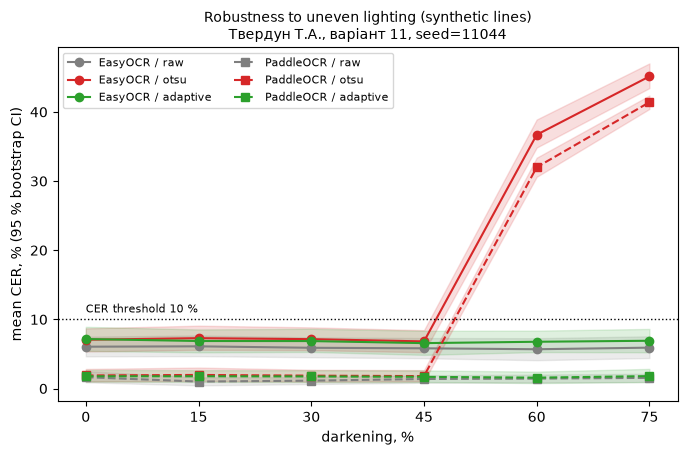

level                           0               15              30  \
engine    prep                                                       
EasyOCR   adaptive  7.2 [5.5; 8.9]  6.9 [5.2; 8.5]  6.9 [5.3; 8.6]   
          otsu      7.1 [5.4; 8.7]  7.3 [5.6; 9.1]  7.1 [5.6; 8.8]   
          raw       6.1 [4.7; 7.5]  6.1 [4.7; 7.7]  5.9 [4.5; 7.4]   
PaddleOCR adaptive  1.8 [1.0; 2.7]  1.8 [1.0; 2.7]  1.7 [0.9; 2.6]   
          otsu      1.9 [1.0; 2.8]  2.0 [1.1; 3.0]  1.9 [1.0; 2.7]   
          raw       1.6 [0.9; 2.5]  1.0 [0.5; 1.6]  1.1 [0.6; 1.7]   

level                           45                 60                 75  
engine    prep                                                            
EasyOCR   adaptive  6.6 [4.9; 8.4]     6.8 [5.3; 8.4]     6.9 [5.2; 8.6]  
          otsu      6.8 [5.2; 8.4]  36.7 [34.8; 38.9]  45.1 [43.4; 47.0]  
          raw       5.8 [4.4; 7.3]     5.7 [4.1; 7.3]     5.9 [4.4; 7.6]  
PaddleOCR adaptive  1.7 [0.9; 2.6]     1.6 [0.8; 2.4]     1.8 [0.9; 2.8]  
          otsu      1.8 [1.0; 2.7]  32.0 [30.6; 33.4]  41.4 [40.4; 42.4]  
          raw       1.4 [0.8; 1.9]     1.4 [0.9; 2.0]     1.5 [1.0; 2.1]

In [39]:
def boot_ci(x, n_boot=2000, alpha=0.05):
    x = np.asarray(x)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.quantile(means, [alpha / 2, 1 - alpha / 2])

CURVE_PREPS = ["raw", "otsu", "adaptive"]
COLORS = {"raw": "tab:gray", "otsu": "tab:red", "adaptive": "tab:green"}
STYLES = {"EasyOCR": "-", "PaddleOCR": "--"}
MARKERS = {"EasyOCR": "o", "PaddleOCR": "s"}

curve_rows = []
fig, ax = plt.subplots(figsize=(8, 4.6))
for eng in ENGINES:
    for prep in CURVE_PREPS:
        g = res[(res["engine"] == eng) & (res["prep"] == prep)]
        by_lvl = g.groupby("level")["cer"]
        mean = by_lvl.mean() * 100
        ci = np.array([boot_ci(v) for _, v in by_lvl]) * 100
        ax.plot(mean.index, mean.values, STYLES[eng], color=COLORS[prep],
                marker=MARKERS[eng], label=f"{eng} / {prep}")
        ax.fill_between(mean.index, ci[:, 0], ci[:, 1], color=COLORS[prep], alpha=0.15)
        for lvl, m, (lo, hi) in zip(mean.index, mean.values, ci):
            curve_rows.append({"engine": eng, "prep": prep, "level": lvl,
                               "cer": m, "ci_low": lo, "ci_high": hi})
ax.axhline(10, ls=":", c="black", lw=1)
ax.text(0, 11, "CER threshold 10 %", fontsize=8)
ax.set_xticks(LEVELS)
ax.set_xlabel("darkening, %")
ax.set_ylabel("mean CER, % (95 % bootstrap CI)")
ax.legend(fontsize=8, ncol=2, loc="upper left")
stamp(ax, "Robustness to uneven lighting (synthetic lines)")
fig.savefig("figures/fig1_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

curve = pd.DataFrame(curve_rows)
curve["ci"] = [f"{c:.1f} [{lo:.1f}; {hi:.1f}]"
               for c, lo, hi in zip(curve["cer"], curve["ci_low"], curve["ci_high"])]
curve.pivot(index=["engine", "prep"], columns="level", values="ci")

**Інтерпретація.** По горизонталі — рівень затемнення правого краю рядка (0–75 %), по вертикалі — середній CER по 40 рядках із 95 % бутстреп-інтервалом (смуга). Орієнтир — допустимий поріг CER = 10 % (пунктир).

*Плато.* Без обробки обидва інструменти не реагують на тінь: EasyOCR 6,1 % при 0 % і 5,9 % при 75 %, PaddleOCR 1,6 % і 1,5 %. Адаптивна бінаризація теж дає плато (EasyOCR 6,6–7,2 %, PaddleOCR 1,6–1,8 %). Жодна з цих кривих не перетинає поріг 10 %.

*Злам.* Крива Оцу лежить на плато до 45 % (EasyOCR 6,8 %, PaddleOCR 1,8 %), а між 45 і 60 % різко злітає до 36,7 % і 32,0 %, а при 75 % — до 45,1 % і 41,4 %. Поріг 10 % обидва інструменти з Оцу вперше перетинають на рівні 60 %. Механізм: Оцу обирає поріг ≈ 135; фон правого краю має яскравість 255 · (1 − рівень), і він стає темнішим за поріг, коли рівень перевищує ≈ 47 %. Саме тому злам лежить між 45 і 60 %.

*Перетин кривих.* Криві EasyOCR і PaddleOCR не перетинаються: PaddleOCR точніший на всіх рівнях, тож вибір інструмента від рівня тіні не залежить.

*Надійність.* Інтервали на плато мають ширину ≈ 3 в. п. для EasyOCR (наприклад, 4,7–7,5 % без обробки при 0 %) і ≈ 1–1,5 в. п. для PaddleOCR. У самій точці зламу (Оцу, 60 %) інтервал найширший — 4,1 в. п. для EasyOCR і 2,8 в. п. для PaddleOCR, бо на межі зламу одні рядки зачеплені тінню мало, а інші сильно; при 75 % інтервали знову вужчі (3,6 і 2,0 в. п.), бо Оцу обрізає праву частину майже всіх рядків. Детальніше — у відповіді на питання 2.

*Висновки:* для документів із нерівним освітленням без обробки або з адаптивною бінаризацією можна працювати аж до 75 % затемнення; глобальний Оцу допустимий лише при затемненні до ≈ 45 %. 

*Додатковий експеримент:* додати рівні 50 і 55 %, щоб точніше знайти точку зламу Оцу, і рівні 85–95 %, щоб знайти, де ламається `raw`.

### 13.2. Діаграма розмаху

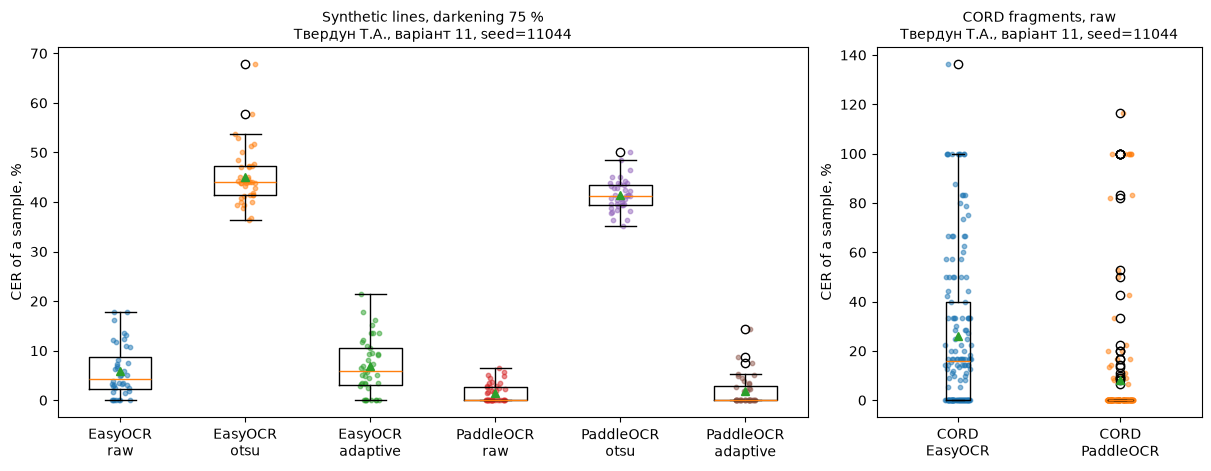

,group,median,mean,"CER = 0, %","CER >= 100, %",max
0,EasyOCR / raw,4.4,5.9,17.5,0.0,17.9
1,EasyOCR / otsu,44.0,45.1,0.0,0.0,67.9
2,EasyOCR / adaptive,5.9,6.9,20.0,0.0,21.4
3,PaddleOCR / raw,0.0,1.5,52.5,0.0,6.5
4,PaddleOCR / otsu,41.2,41.4,0.0,0.0,50.0
5,PaddleOCR / adaptive,0.0,1.8,62.5,0.0,14.3
6,CORD / EasyOCR,16.0,26.2,35.3,6.7,136.4
7,CORD / PaddleOCR,0.0,8.3,82.7,4.7,116.7


In [40]:
synth75 = {f"{eng}\n{prep}": res[(res["level"] == 75) & (res["engine"] == eng) & (res["prep"] == prep)]["cer"] * 100
           for eng in ENGINES for prep in CURVE_PREPS}
cord_raw = {f"CORD\n{eng}": res_cord[(res_cord["engine"] == eng) & (res_cord["prep"] == "raw")]["cer"] * 100
            for eng in ENGINES}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), width_ratios=[3, 1.3], layout="constrained")
for ax, data, title in [(axes[0], synth75, "Synthetic lines, darkening 75 %"),
                        (axes[1], cord_raw, "CORD fragments, raw")]:
    ax.boxplot(list(data.values()), tick_labels=list(data.keys()), showmeans=True)
    for k, g in enumerate(data.values(), start=1):
        ax.scatter(k + rng.uniform(-0.08, 0.08, len(g)), g, s=10, alpha=0.5)
    ax.set_ylabel("CER of a sample, %")
    stamp(ax, title)
fig.savefig("figures/fig2_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

stats = pd.DataFrame([{"group": name.replace("\n", " / "), "median": v.median(), "mean": v.mean(),
                       "CER = 0, %": (v == 0).mean() * 100, "CER >= 100, %": (v >= 100).mean() * 100,
                       "max": v.max()}
                      for d in (synth75, cord_raw) for name, v in d.items()]).round(1)
stats

**Інтерпретація.** Кожна точка — CER одного зразка; коробка охоплює середні 50 % значень, лінія — медіана, трикутник — середнє.

*Синтетика при 75 %.* У PaddleOCR без обробки медіана 0 % при середньому 1,5 %: 52,5 % рядків розпізнано ідеально, а найгірший має 6,5 %. У EasyOCR медіана 4,4 %, середнє 5,9 %, ідеальних рядків лише 17,5 %, найгірший — 17,9 %. З Оцу медіана майже дорівнює середньому (44,0 і 45,1 % в EasyOCR; 41,2 і 41,4 % у PaddleOCR), а точки зібрані щільно від ≈ 35 до ≈ 68 %: Оцу псує кожен рядок приблизно однаково (обрізає праву частину), повних провалів немає.

*CORD без обробки.* Розподіл зовсім інший — правий хвіст із повних провалів. У PaddleOCR медіана 0 % (82,7 % фрагментів ідеальні), а середнє 8,3 %; у EasyOCR медіана 16,0 %, середнє 26,2 %. Повністю провалені фрагменти (CER ≥ 100 %) — 6,7 % у EasyOCR і 4,7 % у PaddleOCR; є навіть CER понад 100 % (до 136 %), коли інструмент вставив більше символів, ніж було в еталоні. Саме ці кілька провалів тягнуть середнє вгору, тому для CORD коректніше повідомляти окремо частку провалів і CER решти фрагментів.

*Висновки:* для реальних даних не можна обмежуватися середнім CER; провали треба виявляти окремо (за впевненістю або порожнім результатом) і відправляти на ручну перевірку. 

*Додатковий експеримент:* відкрити провалені фрагменти CORD і класифікувати причини (детекція, сегментація, заміни символів) — це зроблено в аналізі найгірших зразків.

### 13.3. Впевненість і крива ризик-покриття

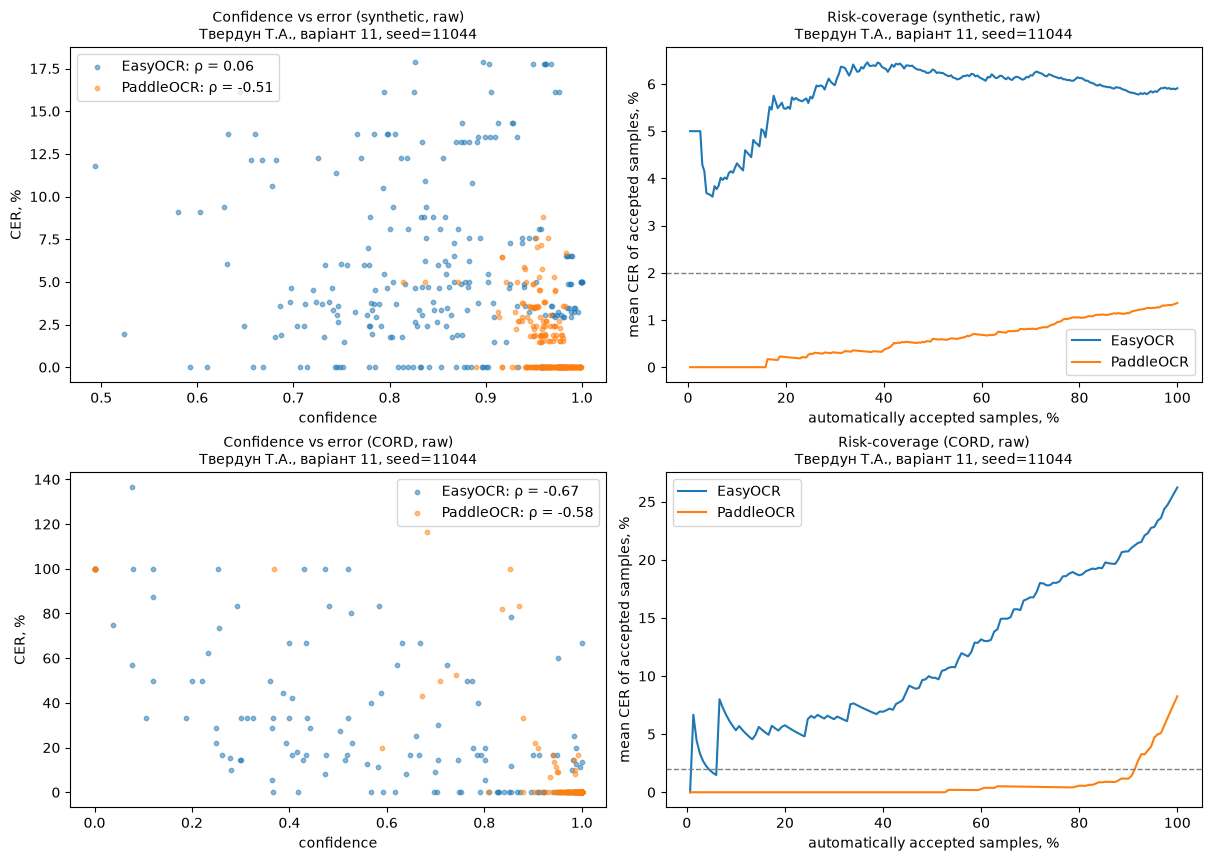

,data,engine,spearman rho,p-value,conf threshold,"auto share, %"
0,"synthetic, raw",EasyOCR,0.062,0.34,NaN,0.000
1,"synthetic, raw",PaddleOCR,-0.511,0.00,0.814,100.000
2,"CORD, raw",EasyOCR,-0.674,0.00,1.000,6.000
3,"CORD, raw",PaddleOCR,-0.582,0.00,0.880,90.667


In [41]:
def risk_coverage(g):
    g = g.sort_values("conf", ascending=False)
    n = np.arange(1, len(g) + 1)
    return n / len(g), g["cer"].cumsum().values / n, g["conf"].values

TARGET = 0.02
conf_rows = []
data_sets = {"synthetic, raw": res[res["prep"] == "raw"],
             "CORD, raw": res_cord[res_cord["prep"] == "raw"]}

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), layout="constrained")
for row, (data_name, d) in zip(axes, data_sets.items()):
    for eng, g in d.groupby("engine"):
        rho, p = spearmanr(g["conf"], g["cer"])
        row[0].scatter(g["conf"], g["cer"] * 100, s=10, alpha=0.5, label=f"{eng}: ρ = {rho:.2f}")
        coverage, risk, confs = risk_coverage(g)
        row[1].plot(coverage * 100, risk * 100, label=eng)
        ok = np.where(risk <= TARGET)[0]
        conf_rows.append({"data": data_name, "engine": eng, "spearman rho": rho, "p-value": p,
                          "conf threshold": confs[ok.max()] if len(ok) else np.nan,
                          "auto share, %": coverage[ok.max()] * 100 if len(ok) else 0.0})
    row[0].set_xlabel("confidence")
    row[0].set_ylabel("CER, %")
    row[0].legend()
    stamp(row[0], f"Confidence vs error ({data_name})")
    row[1].axhline(TARGET * 100, ls="--", c="grey", lw=1)
    row[1].set_xlabel("automatically accepted samples, %")
    row[1].set_ylabel("mean CER of accepted samples, %")
    row[1].legend()
    stamp(row[1], f"Risk-coverage ({data_name})")
fig.savefig("figures/fig3_confidence.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(conf_rows).round(3)

**Інтерпретація.** Ліворуч кожна точка — один зразок (впевненість інструмента проти CER), праворуч — середній CER автоматично прийнятих зразків, якщо приймати їх у порядку спадання впевненості. Орієнтир — допустимий CER = 2 % (пунктир).

*Синтетика.* Впевненість EasyOCR не пов'язана з помилкою: ρ = 0,06 при p = 0,34, тобто зв'язку немає. Навіть найвпевненіші рядки мають CER ≈ 5 %, крива ризик-покриття ніде не опускається нижче 2 %, і порогу для автоматичної обробки не існує. Причина — систематичні помилки, про які інструмент «не знає»: втрата кінцевої крапки та «;» замість «,» (рис. 13.5). Таку помилку неможливо відфільтрувати порогом, її треба виправляти постобробкою. У PaddleOCR зв'язок помірний (ρ = −0,51), але всі рядки мають малий CER: уся крива лежить нижче 2 %, тож при порозі 0,81 автоматично обробляється 100 % рядків.

*CORD.* На реальних даних впевненість корисніша: ρ = −0,67 (EasyOCR) і −0,58 (PaddleOCR). Повністю провалені фрагменти PaddleOCR мають впевненість 0 (інструмент нічого не знайшов), тож їх легко виявити. Для PaddleOCR поріг 0,88 дає 90,7 % фрагментів, оброблених автоматично, із середнім CER ≤ 2 %; після цієї точки крива різко зростає, тобто решта ≈ 9 % містить майже всі помилки. Для EasyOCR вимога CER ≤ 2 % виконується лише для 6 % фрагментів (поріг ≈ 1,00).

*Висновки:* для чеків — PaddleOCR із порогом впевненості 0,88; фрагменти нижче порогу направляти на ручну перевірку (≈ 9 %). Впевненості EasyOCR для відбору не довіряти. 

*Додатковий експеримент:* підібрати поріг на окремій частині CORD (validation) і перевірити на тестовій, щоб поріг не був «підігнаний» під ті самі дані.

### 13.4. Компроміс якість-швидкість

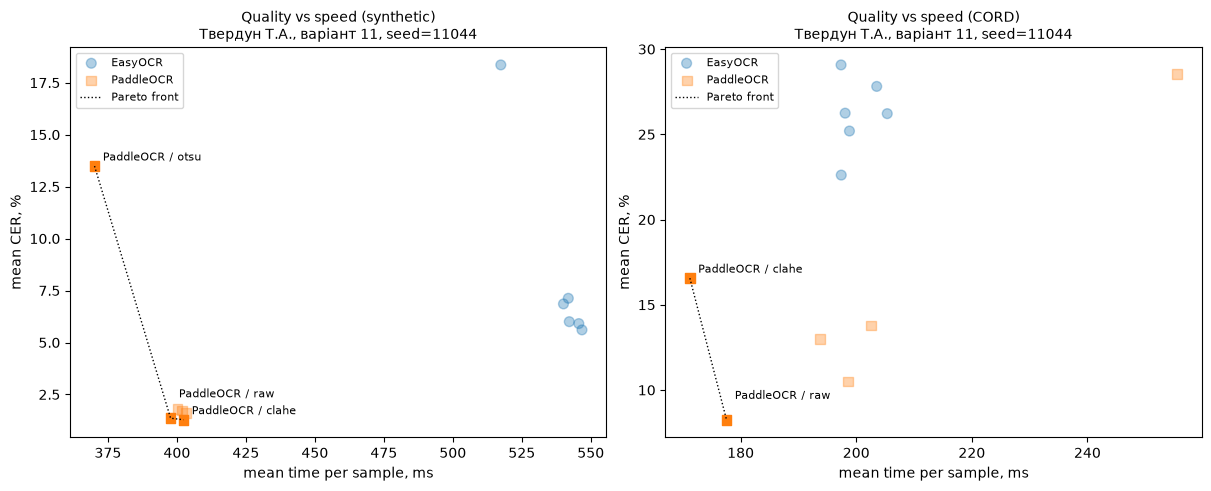

,data,engine,prep,cer,ms,dominated
0,synthetic,EasyOCR,adaptive,6.9,540.1,True
1,synthetic,EasyOCR,clahe,5.6,546.8,True
2,synthetic,EasyOCR,flatten,6.0,542.2,True
3,synthetic,EasyOCR,flatten+otsu,7.1,541.9,True
4,synthetic,EasyOCR,otsu,18.4,517.4,True
5,synthetic,EasyOCR,raw,5.9,545.7,True
6,synthetic,PaddleOCR,adaptive,1.7,401.9,True
7,synthetic,PaddleOCR,clahe,1.3,402.4,False
8,synthetic,PaddleOCR,flatten,1.6,403.2,True
9,synthetic,PaddleOCR,flatten+otsu,1.8,400.2,True


In [42]:
def pareto_table(d):
    agg = d.groupby(["engine", "prep"]).agg(cer=("cer", "mean"), ms=("sec", "mean")).reset_index()
    agg["cer"] *= 100
    agg["ms"] *= 1000
    agg["dominated"] = [((agg["cer"] < c) & (agg["ms"] < t)).any() for c, t in zip(agg["cer"], agg["ms"])]
    return agg

tables = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, (data_name, d) in zip(axes, {"synthetic": res, "CORD": res_cord}.items()):
    agg = pareto_table(d)
    for eng, g in agg.groupby("engine"):
        ax.scatter(g["ms"], g["cer"], s=50, marker=MARKERS[eng], label=eng,
                   alpha=[0.35 if dom else 1.0 for dom in g["dominated"]])
    front = agg[~agg["dominated"]].sort_values("ms")
    ax.plot(front["ms"], front["cer"], ":", c="black", lw=1, label="Pareto front")
    for i, r in enumerate(front.itertuples()):
        ax.annotate(f"{r.engine} / {r.prep}", (r.ms, r.cer), textcoords="offset points",
                    xytext=(6, 4 + 11 * (i % 2)), fontsize=8)
    ax.set_xlabel("mean time per sample, ms")
    ax.set_ylabel("mean CER, %")
    ax.legend(fontsize=8)
    stamp(ax, f"Quality vs speed ({data_name})")
    tables.append(agg.assign(data=data_name))
fig.savefig("figures/fig4_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

pd.concat(tables)[["data", "engine", "prep", "cer", "ms", "dominated"]].round(1)

**Інтерпретація.** Кожна точка — комбінація «інструмент + конфігурація»: середній час розпізнавання одного зразка (без часу попередньої обробки, він становить мілісекунди) і середній CER. Конфігурація домінована, якщо інша водночас швидша і точніша; недоміновані утворюють фронт Парето (пунктир).

*Синтетика.* Усі конфігурації EasyOCR (517–547 мс, CER 5,6–18,4 %) доміновані: PaddleOCR водночас швидший (370–403 мс) і точніший (1,3–13,5 %). На фронті — PaddleOCR з `otsu` (370 мс, 13,5 %), `raw` (398 мс, 1,4 %) і `clahe` (402 мс, 1,3 %). Оцу «найшвидший» лише тому, що обрізаний рядок коротший і розпізнавати менше; різниця між `raw` і `clahe` (4 мс і 0,1 в. п.) лежить у межах похибки вимірювання.

*CORD.* На фронті лише PaddleOCR: `clahe` (171 мс, 16,6 %) і `raw` (178 мс, 8,3 %). Виграш `clahe` у 6 мс — шум, а CER у `raw` удвічі менший. Найкраща конфігурація EasyOCR (`flatten+otsu`, 22,6 %) все одно домінована.

*Висновок (вибір для 10 000 сторінок за ніч):* PaddleOCR без обробки. Ніч ≈ 8 год = 28 800 с, тобто на сторінку є ≈ 2,9 с. На власних фото PaddleOCR витрачав у середньому 6,6 с на сторінку, отже на цьому ноутбуці в один потік 10 000 сторінок оброблялися б ≈ 18 год; потрібні щонайменше 3 паралельні процеси або GPU. EasyOCR (21 с на сторінку, ≈ 58 год) не вкладається навіть із кількома процесами. Час виміряно на CPU з вимкненим прискорювачем oneDNN (вимкнено через помилку PaddlePaddle 3.3), тому з ним PaddleOCR був би ще швидшим.

*Додатковий експеримент:* повторити вимірювання часу кілька разів (наприклад, 3 запуски кожної конфігурації) і порахувати інтервал для часу — це покаже, чи різниці в кілька мілісекунд (`raw` проти `clahe`) реальні, чи це шум. Окремо — заміряти швидкість PaddleOCR з увімкненим oneDNN на версії PaddlePaddle без цієї помилки (наприклад, 3.2) і з паралельною обробкою в кількох процесах, щоб перевірити, чи вкладеться 10 000 сторінок у 8 годин.

### 13.5. Найчастіші заміни символів

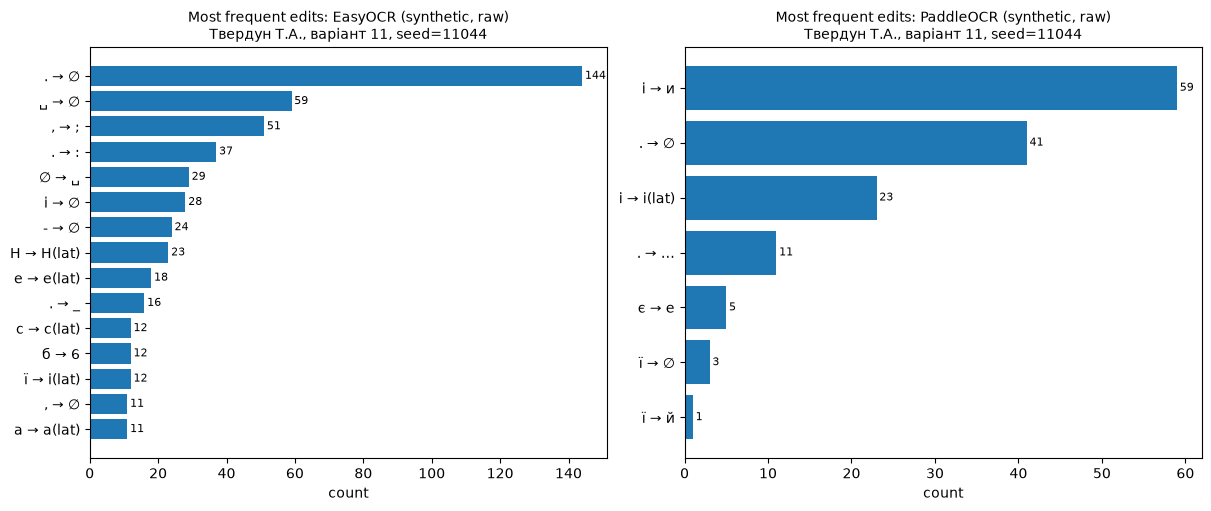

In [43]:
def sym(c):
    if c == " ":
        return "␣"
    if c.isascii() and c.isalpha():
        return c + "(lat)"
    return c

def confusions(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    pairs = []
    for op in Levenshtein.editops(gt, pred):
        if op.tag == "replace":
            pairs.append(f"{sym(gt[op.src_pos])} → {sym(pred[op.dest_pos])}")
        elif op.tag == "delete":
            pairs.append(f"{sym(gt[op.src_pos])} → ∅")
        else:
            pairs.append(f"∅ → {sym(pred[op.dest_pos])}")
    return pairs

top_conf = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, eng in zip(axes, ENGINES):
    part = res[(res["engine"] == eng) & (res["prep"] == "raw") & (res["cer"] < 0.5)]
    cnt = Counter()
    for g, p in zip(part["gt"], part["pred"]):
        cnt.update(confusions(g, p))
    top = pd.Series(dict(cnt.most_common(15)))
    top_conf[eng] = top
    ax.barh(top.index[::-1], top.values[::-1])
    ax.bar_label(ax.containers[0], fontsize=8, padding=2)
    ax.set_xlabel("count")
    stamp(ax, f"Most frequent edits: {eng} (synthetic, raw)")
fig.savefig("figures/fig6_confusions.png", dpi=150, bbox_inches="tight")
plt.show()

**Інтерпретація.** Діаграма показує 15 найчастіших операцій редагування на синтетиці без обробки (лише рядки з CER < 50 %): заміни «а → б», видалення «а → ∅» та вставлення «∅ → б»; ␣ — пробіл, (lat) — латинська літера.

*EasyOCR.* Найчастіша помилка — втрата кінцевої крапки (144 випадки; майже кожен рядок закінчується розділовим знаком). Далі — пропущені пробіли (59, слова зливаються), «,» → «;» (51) і «.» → «:» (37); пропуск окремого слова-сполучника «і» (28). Окрема група — гомогліфи: кириличні літери замінено латинськими двійниками (Н → H 23, е → e 18, с → c 12, ї → i 12, а → a 11; разом ≈ 76 випадків), а також «б» → «6» (12). Причина гомогліфів — модель `uk + en` має спільний набір символів, і для однакових на вигляд літер обирає латинську. Ці помилки невидимі для людини, але ламають пошук і зіставлення даних.

*PaddleOCR.* Помилок значно менше. Найчастіша — «і» → «и» (59): модель `eslav` навчена разом на російській, українській і білоруській мовах і плутає українську «і» з російською «и» (та сама помилка на чеках: «Львив», «пристрий»). Далі — втрата крапки (41), «і» → латинська «i» (23) і злиття «...» в один символ «…» (11).

*Висновок:* більшість помилок систематичні, тому їх можна зменшити постобробкою, а не вибором порогу чи іншої обробки зображення: замінювати латинські двійники всередині кириличних слів на кириличні, «…» → «...», «и» → «і» в словах, яких немає в українському словнику.

*Додатковий експеримент:* (1) застосувати ці правила до результатів і виміряти, на скільки зменшиться CER — це зроблено в розділі 14; (2) щоб перевірити пояснення про гомогліфи, повторити розпізнавання EasyOCR лише з українською мовою (`["uk"]` без `"en"`): якщо причина у спільному наборі латинських і кириличних символів, заміни на кшталт Н → H(lat) мають зникнути або стати значно рідшими.

### 13.6. Порівняння трьох груп даних

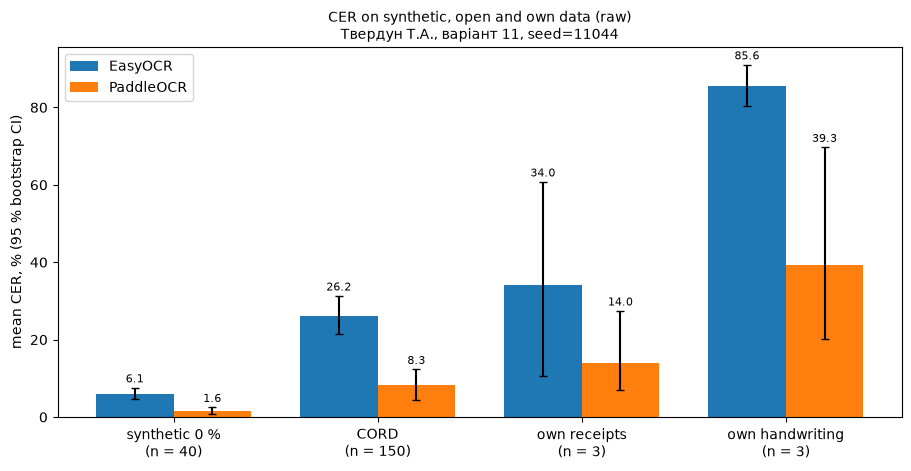

,group,engine,n,cer,ci_low,ci_high,x synthetic
0,synthetic 0 %,EasyOCR,40,6.1,4.6,7.6,1.0
1,synthetic 0 %,PaddleOCR,40,1.6,0.9,2.5,1.0
2,CORD,EasyOCR,150,26.2,21.4,31.3,4.3
3,CORD,PaddleOCR,150,8.3,4.4,12.3,5.0
4,own receipts,EasyOCR,3,34.0,10.6,60.7,5.6
5,own receipts,PaddleOCR,3,14.0,7.0,27.4,8.5
6,own handwriting,EasyOCR,3,85.6,80.3,91.0,14.1
7,own handwriting,PaddleOCR,3,39.3,20.2,69.7,24.0


In [44]:
own_raw = res_own[res_own["prep"] == "raw"]
groups = {
    "synthetic 0 %": res[(res["prep"] == "raw") & (res["level"] == 0)],
    "CORD": res_cord[res_cord["prep"] == "raw"],
    "own receipts": own_raw[own_raw["name"].str.startswith("receipt")],
    "own handwriting": own_raw[own_raw["name"].str.startswith("page")],
}

comp_rows = []
for gname, d in groups.items():
    for eng in ENGINES:
        v = d[d["engine"] == eng]["cer"].values
        lo, hi = boot_ci(v)
        comp_rows.append({"group": gname, "engine": eng, "n": len(v),
                          "cer": v.mean() * 100, "ci_low": lo * 100, "ci_high": hi * 100})
comp = pd.DataFrame(comp_rows)

fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
x = np.arange(len(groups))
for k, eng in enumerate(ENGINES):
    c = comp[comp["engine"] == eng]
    bars = ax.bar(x + (k - 0.5) * 0.38, c["cer"], width=0.38, label=eng,
                  yerr=[c["cer"] - c["ci_low"], c["ci_high"] - c["cer"]], capsize=3)
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
n_per_group = comp[comp["engine"] == "EasyOCR"]["n"]
ax.set_xticks(x, [f"{g}\n(n = {n})" for g, n in zip(groups, n_per_group)])
ax.set_ylabel("mean CER, % (95 % bootstrap CI)")
ax.legend()
stamp(ax, "CER on synthetic, open and own data (raw)")
fig.savefig("figures/fig7_groups.png", dpi=150, bbox_inches="tight")
plt.show()

base = comp[comp["group"] == "synthetic 0 %"].set_index("engine")["cer"]
comp["x synthetic"] = comp["cer"] / comp["engine"].map(base)
comp.round(1)

**Інтерпретація.** Середній CER без попередньої обробки на чотирьох групах даних з 95 % бутстреп-інтервалами; n — кількість зразків.

На синтетиці без тіні (n = 40) CER становить 6,1 % (EasyOCR) і 1,6 % (PaddleOCR). На реальних фрагментах чеків CORD (n = 150) — 26,2 % і 8,3 %, тобто у 4,3 і 5,0 раза більше: це прояв розриву між доменами (domain gap) — розмиття, низька роздільність, матричний друк і текстура паперу, яких немає в синтетиці. Власні чеки з тінню (n = 3) дають 34,0 % і 14,0 % (у 5,6 і 8,5 раза більше, ніж синтетика, і в 1,3–1,7 раза більше, ніж CORD), але їхні інтервали (10,6–60,7 % і 7,0–27,4 %) перекриваються з інтервалами CORD, тож на трьох чеках не можна надійно стверджувати, що вони важчі. Рукописна сторінка — найважча група: 85,6 % і 39,3 % (у 14 і 24 рази гірше за синтетику), бо обидва інструменти навчені на друкованому тексті. Найгірша умова зйомки сторінки для EasyOCR — бічне світло з тінню (91,0 %), для PaddleOCR — зйомка під кутом (69,7 %).

PaddleOCR точніший в усіх чотирьох групах; найбільший абсолютний відрив — на рукописі (46 в. п.).

*Надійність:* для власних фото n = 3, тому інтервали дуже широкі (наприклад, 10,6–60,7 % для чеків в EasyOCR), і висновки щодо них орієнтовні.

*Висновок:* результати на синтетиці переоцінюють якість у 4–24 рази, тому вибір інструмента і попередньої обробки треба перевіряти на реальних даних. Для чеків варто обрати PaddleOCR (8,3 % на CORD, 14,0 % на власних чеках); для рукопису обидва інструменти непридатні, потрібні спеціалізовані моделі HTR (наприклад, TrOCR, донавчений на українському рукописі).

*Додатковий експеримент:* сфотографувати більше сторінок і чеків (щонайменше 10–15 кожного типу), щоб звузити інтервали й перевірити, чи власні чеки справді важчі за CORD; для рукопису — порівняти з TrOCR на тих самих трьох фото.

## 14. Індивідуальні питання

### 14.1. Питання 1: перевищення порогу 10 % і перетин кривих

*Питання: на якому рівні чинника CER уперше перевищує 10 %? Чи перетинаються криві?*

Поріг 10 % перетинає лише конфігурація з глобальною бінаризацією Оцу, для обох інструментів на рівні затемнення **60 %**: EasyOCR — 6,8 % при 45 % → 36,7 % при 60 %; PaddleOCR — 1,8 % → 32,0 %. Без обробки і з адаптивною бінаризацією CER не перевищує 10 % на жодному рівні (максимум 6,1 % і 7,2 % для EasyOCR, 1,6 % і 1,8 % для PaddleOCR), тобто для них точки зламу в дослідженому діапазоні 0–75 % немає.

Криві **інструментів** не перетинаються: PaddleOCR має менший CER на всіх рівнях (без обробки — на 4,3–5,1 в. п.), тому вибір інструмента від рівня тіні не залежить. Натомість перетинаються криві **конфігурацій**: між 45 і 60 % крива Оцу перетинає криві `raw` і `adaptive`. Отже, вибір бінаризації залежить від умов: при затемненні до ≈ 45 % Оцу працює не гірше за інші (у межах 1 в. п.), а при сильнішій тіні його використовувати не можна.

### 14.2. Питання 2: ширина інтервалів і розмір вибірки

In [45]:
curve["width"] = curve["ci_high"] - curve["ci_low"]
print(curve.pivot_table(index=["engine", "prep"], columns="level", values="width").round(1))

worst = curve.sort_values("width").iloc[-1]
eng_w, prep_w, lvl_w = worst["engine"], worst["prep"], int(worst["level"])
print(f"Widest interval: {eng_w} / {prep_w} / {lvl_w} %, width {worst['width']:.1f} pp")

EXTRA = 120
used = set(lines)
rest = [s for s in corpus if s not in used]
extra_lines = [str(s) for s in rng.choice(rest, size=EXTRA, replace=False)]

extra_cer = []
for i, sentence in enumerate(extra_lines):
    img = degrade(render_line(sentence, FONTS[i % len(FONTS)], size=int(rng.integers(22, 36))), lvl_w)
    text, conf, sec = ENGINES[eng_w](preprocess(img, PREP[prep_w]), "uk")
    extra_cer.append(cer(sentence, text))

base_cer = res[(res["engine"] == eng_w) & (res["prep"] == prep_w) & (res["level"] == lvl_w)]["cer"].values
all_cer = np.concatenate([base_cer, extra_cer])
for name, v in [("original", base_cer), ("extended", all_cer)]:
    lo, hi = boot_ci(v)
    print(f"{name}: n = {len(v)}, mean CER {v.mean() * 100:.1f} %, "
          f"95 % CI [{lo * 100:.1f}; {hi * 100:.1f}], width {(hi - lo) * 100:.1f} pp")

level                0    15   30   45   60   75
engine    prep                                  
EasyOCR   adaptive  3.5  3.3  3.4  3.5  3.1  3.4
          otsu      3.3  3.5  3.3  3.2  4.1  3.6
          raw       2.8  3.0  2.9  2.9  3.2  3.1
PaddleOCR adaptive  1.7  1.7  1.7  1.7  1.7  1.9
          otsu      1.8  1.9  1.7  1.6  2.8  2.0
          raw       1.6  1.2  1.0  1.1  1.1  1.2
Widest interval: EasyOCR / otsu / 60 %, width 4.1 pp
original: n = 40, mean CER 36.7 %, 95 % CI [34.8; 39.0], width 4.2 pp
extended: n = 160, mean CER 37.5 %, 95 % CI [36.3; 38.8], width 2.4 pp


*Питання: порівняйте ширину довірчих смуг на плато і в зоні зламу. Скільки зразків треба додати, щоб удвічі звузити інтервал у найгіршій точці? Перевірте оцінку.*

**Плато і злам.** На плато (0–45 %) ширина 95 % інтервалу становить 2,8–3,5 в. п. для EasyOCR і 1,0–1,9 в. п. для PaddleOCR. У точці зламу Оцу (60 %) інтервал помітно ширшає: 4,1 в. п. для EasyOCR (проти 3,2–3,5 на плато) і 2,8 в. п. для PaddleOCR (проти 1,6–1,9). При 75 % він знову звужується (3,6 і 2,0 в. п.). Пояснення: при 60 % частина рядків лише трохи зачеплена тінню нижче порогу Оцу, а частина втрачає великий шматок (залежно від довжини рядка й розміру шрифту), тому розкид CER між рядками найбільший; при 75 % обрізаються майже всі рядки, і розкид знову менший. Найширший інтервал — EasyOCR з Оцу при 60 % (4,1 в. п.).

**Оцінка.** Ширина інтервалу середнього пропорційна 1/√n, тому для звуження вдвічі потрібно в 4 рази більше зразків: 40 × 4 = 160, тобто треба додати 120 рядків.

**Перевірка.** До 40 рядків у найгіршій точці (EasyOCR, Оцу, 60 %) додано 120 нових речень із корпусу «Лісової пісні», яких не було в початковій вибірці. Для n = 40 середній CER становив 36,7 % з інтервалом [34,8; 39,0] (ширина 4,2 в. п.), для n = 160 — 37,5 % з інтервалом [36,3; 38,8] (ширина 2,4 в. п.). Інтервал звузився в 1,75 раза — близько до теоретичних 2 разів; невелике відхилення пояснюється випадковістю бутстрепу і тим, що нові рядки мають трохи більший розкид CER. Нове середнє (37,5 %) лежить у межах початкового інтервалу, тобто оцінку на 40 рядках збільшення вибірки підтвердило.

### 14.3. Питання 3: парна різниця між інструментами

In [46]:
pair = res[res["prep"] == "raw"].pivot_table(index=["level", "id"], columns="engine", values="cer")
pair["diff"] = pair["EasyOCR"] - pair["PaddleOCR"]

by_level = pair.groupby("level")["diff"].mean() * 100
worst_level = by_level.abs().idxmax()
d = pair.loc[worst_level, "diff"].values
lo, hi = boot_ci(d)

print("Mean difference EasyOCR - PaddleOCR by level, pp:", by_level.round(1).to_dict())
print(f"Largest difference at {worst_level} %: {d.mean() * 100:.1f} pp, "
      f"95 % CI [{lo * 100:.1f}; {hi * 100:.1f}] ->",
      "contains 0" if lo <= 0 <= hi else "does not contain 0")
print("Lines where PaddleOCR is better / equal / worse:",
      (d > 0).sum(), "/", (d == 0).sum(), "/", (d < 0).sum())

Mean difference EasyOCR - PaddleOCR by level, pp: {0: 4.4, 15: 5.1, 30: 4.8, 45: 4.4, 60: 4.2, 75: 4.4}
Largest difference at 15 %: 5.1 pp, 95 % CI [3.8; 6.6] -> does not contain 0
Lines where PaddleOCR is better / equal / worse: 31 / 8 / 1


*Питання: для рівня, де різниця між інструментами найбільша, обчисліть бутстреп-інтервал парної різниці CER. Чи містить він нуль?*

Без попередньої обробки EasyOCR має більший CER, ніж PaddleOCR, на всіх рівнях затемнення; середня різниця становить 4,2–5,1 в. п. Найбільша вона при затемненні **15 %**: **5,1 в. п.** Оскільки обидва інструменти розпізнавали ті самі 40 рядків, порівнювалися різниці CER для кожного рядка (парний бутстреп, 2000 вибірок): 95 % інтервал різниці — **[3,8; 6,6] в. п.**, він **не містить нуля**. PaddleOCR кращий на 31 рядку з 40, однаковий на 8 і гірший лише на 1.

Отже, перевага PaddleOCR на синтетичних рядках статистично надійна навіть на 40 зразках. Парне порівняння точніше, ніж порівняння двох окремих інтервалів, бо прибирає вплив того, що одні рядки складніші за інші: однаково складний рядок погіршує результат обох інструментів, а на різницю не впливає.

### 14.4. Питання 4: медіана, середнє і повні провали

Share of complete failures (CER >= 100 %): {'EasyOCR': 6.7, 'PaddleOCR': 4.7}


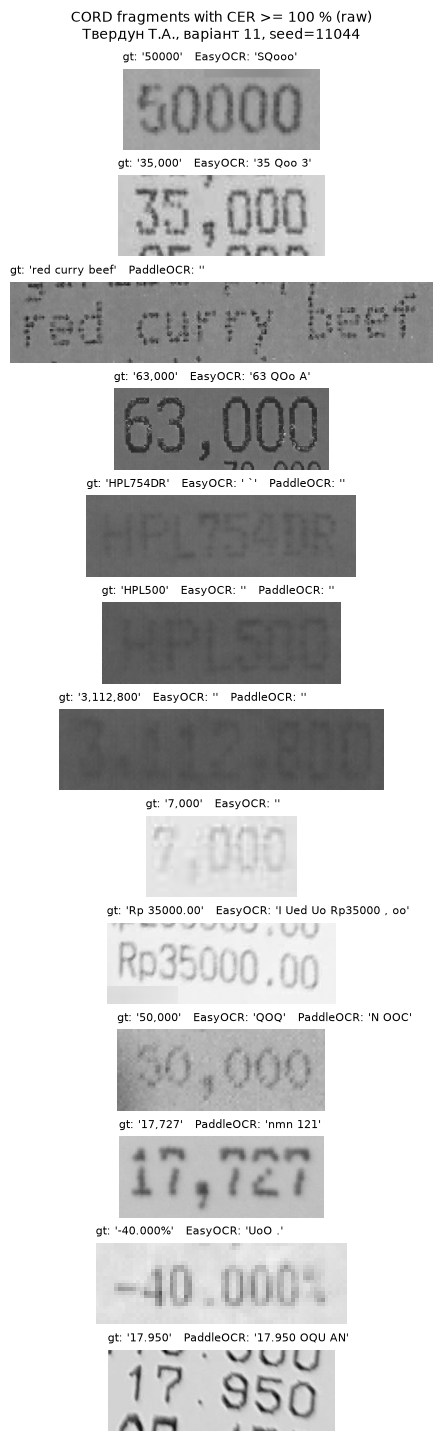

In [47]:
raw_cord = res_cord[res_cord["prep"] == "raw"].merge(
    sample[["receipt", "line", "seg", "path"]], on=["receipt", "line", "seg"])
fails = raw_cord[raw_cord["cer"] >= 1].sort_values(["receipt", "line", "seg", "engine"])
fails = fails.assign(pred=fails["pred"].fillna(""))
print("Share of complete failures (CER >= 100 %):",
      (fails.groupby("engine").size() / raw_cord.groupby("engine").size() * 100).round(1).to_dict())

uniq = fails.drop_duplicates("path")
fig, axes = plt.subplots(len(uniq), 1, figsize=(7, 1.1 * len(uniq)), layout="constrained")
for ax, row in zip(axes, uniq.itertuples()):
    f = fails[fails["path"] == row.path]
    preds = "   ".join(f"{e}: {p!r}" for e, p in zip(f["engine"], f["pred"]))
    ax.imshow(cv2.imread(row.path, cv2.IMREAD_GRAYSCALE), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"gt: {row.gt!r}   {preds}", fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"CORD fragments with CER >= 100 % (raw)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig_cord_failures.png", dpi=150, bbox_inches="tight")
plt.show()

*Питання: порівняйте медіану і середнє CER на діаграмі розмаху. Яка частка зразків має CER = 1 (повний провал)? Відкрийте ці зображення і назвіть причину.*

**Медіана і середнє.** На синтетиці медіана близька до середнього, бо повних провалів немає: з Оцу при 75 % — 44,0 і 45,1 % (EasyOCR), 41,2 і 41,4 % (PaddleOCR); Оцу псує кожен рядок приблизно однаково. Без обробки в PaddleOCR медіана 0 % при середньому 1,5 % (більше половини рядків ідеальні). На CORD розрив великий: медіана 16,0 % і середнє 26,2 % в EasyOCR, медіана 0 % і середнє 8,3 % у PaddleOCR. Середнє тягнуть угору кілька повних провалів (правий хвіст розподілу), тому для CORD середній CER гірше описує типовий фрагмент, ніж медіана.

**Частка повних провалів (CER ≥ 100 %) на CORD:** 6,7 % у EasyOCR (10 фрагментів зі 150) і 4,7 % у PaddleOCR (7 фрагментів). На синтетиці повних провалів немає в жодній конфігурації.

**Причини** (13 провалених фрагментів, рисунок вище):
1. **Відмова детекції — дуже низький контраст** (порожній результат, впевненість 0). Три фрагменти чека 39 («HPL754DR», «HPL500», «3,112,800») надруковано темно-сірим по сірому фону, і обидва інструменти не знайшли там тексту; вицвілий «7,000» не знайшов EasyOCR. Матричний «red curry beef» з крапковими літерами не знайшов PaddleOCR.
2. **Заміна цифр літерами (гомогліфи цифра/літера)** — лише EasyOCR: нулі прочитано як O, o, Q («50000» → «SQooo», «35,000» → «35 Qoo 3», «63,000» → «63 QOo A»). Англійська модель EasyOCR плутає 0 і O у касовому шрифті; CER = 100 %, бо майже кожен символ замінено, а деякі вставлено.
3. **Сусідні рядки у вирізці (помилка сегментації)**: у фрагменти «Rp 35000.00» і «17.950» потрапили шматки рядків вище й нижче, і інструмент їх теж прочитав («17.950 OQU AN»). Через вставлені символи CER перевищує 100 % (136 % і 117 %).
4. **Розмитий і низький шрифт**: «17,727» PaddleOCR прочитав як «nmn 121» з впевненістю 0,85; «-40.000%» висотою лише 18 пікселів EasyOCR прочитав як «UoO .». Цей тип провалу небезпечний, бо впевненість висока і порогом його не відсіяти.

Типи 1 і 3 виникають ще до розпізнавання (на етапі детекції та вирізання), і їх неможливо виправити постобробкою тексту — це узгоджується з тезою методички, що помилки ранніх етапів конвеєра не компенсуються пізнішими.

### 14.5. Питання 5: коефіцієнт Спірмена і поріг впевненості

*Питання: назвіть коефіцієнт Спірмена для кожного інструмента. Який поріг впевненості забезпечує середній CER прийнятих зразків не більше 2 % і яку частку даних при цьому буде оброблено автоматично?*

| Дані (без обробки) | Інструмент | ρ Спірмена | Поріг для CER ≤ 2 % | Частка автоматично |
|---|---|---|---|---|
| синтетика | EasyOCR | 0,06 (p = 0,34) | не існує | 0 % |
| синтетика | PaddleOCR | −0,51 (p < 0,001) | 0,81 | 100 % |
| CORD | EasyOCR | −0,67 (p < 0,001) | ≈ 1,00 | 6 % |
| CORD | PaddleOCR | −0,58 (p < 0,001) | 0,88 | 90,7 % |

На синтетиці впевненість EasyOCR не пов'язана з помилкою (ρ = 0,06, зв'язок статистично незначущий): його основні помилки (втрата кінцевої крапки, «;» замість «,») систематичні, і інструмент упевнений у них так само, як у правильних рядках. Тому порогу, що дає CER ≤ 2 %, не існує — навіть найвпевненіші рядки мають CER ≈ 5 %. У PaddleOCR усі синтетичні рядки мають малий CER, тож при порозі 0,81 автоматично обробляється 100 %.

На реальних чеках CORD впевненість обох інструментів пов'язана з помилкою (ρ = −0,67 і −0,58). Для PaddleOCR поріг **0,88** дозволяє автоматично обробити **90,7 %** фрагментів із середнім CER ≤ 2 %; решту ≈ 9 % треба направляти на ручну перевірку. Для EasyOCR така якість досягається лише для 6 % фрагментів, тобто для практичного відбору він непридатний. Обмеження: є провали з високою впевненістю (PaddleOCR прочитав «17,727» як «nmn 121» з впевненістю 0,85), тож поріг не відсіює всі помилки.

### 14.6. Питання 6: доміновані конфігурації і вибір для 10 000 сторінок

*Питання: які конфігурації на діаграмі «час-CER» домінуються іншими? Яку конфігурацію ви обрали б для обробки 10 000 сторінок за ніч і чому?*

**Доміновані конфігурації.** На синтетиці доміновані всі шість конфігурацій EasyOCR (517–547 мс, CER 5,6–18,4 %), а також `adaptive`, `flatten` і `flatten+otsu` PaddleOCR. На фронті Парето — PaddleOCR з `otsu` (370 мс, 13,5 %), `raw` (398 мс, 1,4 %) і `clahe` (402 мс, 1,3 %). На CORD доміновані всі конфігурації EasyOCR і PaddleOCR з `adaptive`, `flatten`, `flatten+otsu` і `otsu`; на фронті — PaddleOCR з `clahe` (171 мс, 16,6 %) і `raw` (178 мс, 8,3 %).

Частина «недомінованих» конфігурацій потрапила на фронт формально: Оцу на синтетиці швидший лише тому, що обрізаний рядок коротший, а різниці 4–6 мс між `raw` і `clahe` лежать у межах похибки вимірювання часу.

**Вибір для 10 000 сторінок за ніч: PaddleOCR без обробки.** Він має найменший CER на синтетиці (1,4 %) і на CORD (8,3 %) та практично найменший час. Ніч ≈ 8 год = 28 800 с, тобто на сторінку є ≈ 2,9 с. На власних фото PaddleOCR витрачав 6,6 с на сторінку, тому на цьому ноутбуці в один процес 10 000 сторінок оброблялися б ≈ 18 год; потрібно щонайменше 3 паралельні процеси або GPU. EasyOCR (21 с на сторінку) потребував би ≈ 58 год. Разом із порогом впевненості 0,88 (питання 5) ≈ 9 % сторінок слід передавати на ручну перевірку.

### 14.7. Питання 7: внесок кроків попередньої обробки

*Питання: який крок попередньої обробки дав найбільший приріст, а який погіршив результат? Чи збігається це з вашою гіпотезою? Поясніть механізм.*

**Погіршив найбільше — глобальна бінаризація Оцу при сильній тіні.** При затемненні 75 % CER зріс з 5,9 до 45,1 % (EasyOCR, +39,2 в. п.) і з 1,5 до 41,4 % (PaddleOCR, +39,9 в. п.). Механізм: Оцу обирає один поріг (≈ 135) для всього зображення; фон правого краю, затемнений до ≈ 63, стає темнішим за поріг і разом із текстом перетворюється на чорну пляму, тож кінець рядка зникає (рис. 7.2). Це **підтверджує гіпотезу Г2** (CER > 30 % при 60–75 %).

**Найбільший приріст — вирівнювання освітлення перед Оцу.** `flatten+otsu` при 75 % дає 7,1 % (EasyOCR) і 1,7 % (PaddleOCR) замість 45,1 % і 41,4 % з самим Оцу, тобто «рятує» його на 38–40 в. п. Механізм: оцінка фону (морфологічне закриття 15 × 15 стирає тонкі штрихи тексту) і ділення на неї прибирає множник освітлення, після чого один глобальний поріг знову розділяє текст і фон. Це показує, що ефект кроку залежить від інших кроків. Адаптивна бінаризація теж нейтралізує тінь (6,9 % і 1,8 % при 75 %), що **підтверджує Г3**.

**Відносно базового варіанта `raw` жоден крок на синтетиці надійно не покращив результат:** найкращий CLAHE (5,4 % проти 5,9 % для EasyOCR при 75 %) виграє менше, ніж ширина довірчого інтервалу (≈ 3 в. п.). На чистих рядках будь-яка бінаризація трохи шкодить (EasyOCR при 0 %: 6,1 % без обробки, 7,1 % з Оцу, 7,2 % з адаптивною), бо нейромережі навчені на сірих природних зображеннях.

**Неочікуваний результат на реальних даних** (гіпотезами не передбачений): на CORD адаптивна бінаризація погіршила PaddleOCR з 8,3 до 28,5 % (+20,2 в. п.). Параметри (вікно 31, зсув 15) підібрані для великих синтетичних рядків; на малих фрагментах CORD (висота від 16 пікселів) з вицвілим матричним друком локальний поріг стирає бліді крапки, з яких складаються літери. Для EasyOCR на CORD невеликий приріст дав `flatten+otsu` (26,2 → 22,6 %). На власних чеках із різкою тінню адаптивна бінаризація скрізь значно краща за Оцу (наприклад, чек 2 у PaddleOCR: 32,6 % проти 88,4 %), але PaddleOCR без обробки здебільшого все одно найточніший.

### 14.8. Питання 8: правила постобробки

In [48]:
LAT2CYR = str.maketrans("aceiopxyABCEHIKMOPTX", "асеіорхуАВСЕНІКМОРТХ")

def fix_homoglyphs(text):
    out = []
    for w in text.split(" "):
        core = w.strip('.,;:!?…"()-')
        if re.search(r"[\u0400-\u04FF]", w) or len(core) == 1:
            w = w.translate(LAT2CYR)
        out.append(w)
    return " ".join(out)

def fix_ellipsis(text):
    return text.replace("…", "...")

def add_final_period(text):
    if text and not text.endswith(tuple('.!?…"')):
        text += "."
    return text

RULES = {"homoglyphs": fix_homoglyphs, "ellipsis": fix_ellipsis, "final period": add_final_period}

def apply_rules(text, names):
    text = normalize(text)
    for n in names:
        text = RULES[n](text)
    return text

rows = []
for eng, g in res[res["prep"] == "raw"].groupby("engine"):
    before = g["cer"].values
    row = {"engine": eng, "no rules": before.mean() * 100}
    for name in RULES:
        row[name] = np.mean([cer(t, apply_rules(p, [name])) for t, p in zip(g["gt"], g["pred"])]) * 100
    after = np.array([cer(t, apply_rules(p, list(RULES))) for t, p in zip(g["gt"], g["pred"])])
    row["all three"] = after.mean() * 100
    row["lines better"] = int((after < before).sum())
    row["lines worse"] = int((after > before).sum())
    rows.append(row)
pd.DataFrame(rows).round(2)

,engine,no rules,homoglyphs,ellipsis,final period,all three,lines better,lines worse
0,EasyOCR,5.91,5.70,5.91,4.96,4.75,92,0
1,PaddleOCR,1.36,1.19,1.16,1.36,0.98,30,1


*Питання: назвіть п'ять найчастіших помилок на діаграмі замін. Для трьох з них запропонуйте правило постобробки і виміряйте, як воно змінює CER.*

**П'ять найчастіших помилок** (синтетика без обробки, рис. 13.5):
- EasyOCR: втрата кінцевої крапки «. → ∅» (144), пропущений пробіл «␣ → ∅» (59), «, → ;» (51), «. → :» (37), зайвий пробіл «∅ → ␣» (29); далі — латинські двійники кириличних літер (Н → H, е → e, с → c тощо);
- PaddleOCR: «і → и» (59), «. → ∅» (41), «і → латинська i» (23), «. → …» (11), «є → е» (5).

**Правила і їхній ефект** (середній CER на 240 синтетичних рядках без обробки):

| Правило | EasyOCR | PaddleOCR |
|---|---|---|
| без правил | 5,91 % | 1,36 % |
| гомогліфи: латинські двійники в кириличних словах → кирилиця | 5,70 % | 1,19 % |
| «…» → «...» | 5,91 % | 1,16 % |
| кінцева крапка, якщо рядок не закінчується розділовим знаком | 4,96 % | 1,36 % |
| усі три разом | **4,75 %** (−1,16 в. п., −20 %) | **0,98 %** (−0,38 в. п., −28 %) |

Кожне правило виправляє саме «свою» помилку: кінцева крапка дає найбільший виграш для EasyOCR (−0,95 в. п.), але не діє на PaddleOCR, який крапку майже не губить; «…» → «...» діє лише на PaddleOCR. Разом правила покращили 92 рядки EasyOCR і 30 рядків PaddleOCR. Погіршився лише один рядок: PaddleOCR повернув «її….» (три крапки одним символом плюс ще одна), і правило перетворило це на п'ять крапок замість трьох.

**Обмеження.** Правило кінцевої крапки спирається на властивість корпусу (кожне речення закінчується розділовим знаком) і не підходить для фрагментів чеків, де крапки в кінці немає. Помилки «, → ;» правилом не виправити, бо справжні «;» теж є в тексті. Найчастішу помилку PaddleOCR «і → и» можна виправляти лише за словником (наприклад, hunspell для української мови): замінювати «и» на «і», якщо отримане слово є в словнику, а вихідне — ні.

### 14.9. Питання 9: власні фото проти синтетичних і відкритих даних

*Питання: у скільки разів CER на власних фотографіях відрізняється від CER на синтетичних і відкритих даних? Яка з трьох умов зйомки рукописної сторінки найгірша для кожного інструмента?*

**Порівняння груп** (без обробки, рис. 13.6):

| Група | EasyOCR | PaddleOCR | у скільки разів гірше за синтетику | у скільки разів гірше за CORD |
|---|---|---|---|---|
| синтетика, 0 % (n = 40) | 6,1 % | 1,6 % | 1× | — |
| CORD (n = 150) | 26,2 % | 8,3 % | 4,3× / 5,0× | 1× |
| власні чеки (n = 3) | 34,0 % | 14,0 % | 5,6× / 8,5× | 1,3× / 1,7× |
| власний рукопис (n = 3) | 85,6 % | 39,3 % | 14,1× / 24,0× | 3,3× / 4,7× |

Власні чеки за складністю близькі до CORD (у 1,3–1,7 раза гірші), бо це той самий тип даних; додаткова складність — різка тінь від руки, українська мова і змішування кирилиці з латиницею. Проте при n = 3 їхні інтервали перекриваються з CORD, тож різниця ненадійна. Рукопис у 14–24 рази гірший за синтетику, бо обидва інструменти навчені на друкованому тексті.

**Найгірша умова зйомки сторінки** (таблиця 12.2):
- **EasyOCR — бічне світло з тінню: 91,0 %** (рівне світло 80,3 %, під кутом 85,4 %). Утім, усі три значення близькі до повного провалу, тож EasyOCR рукопис фактично не читає за жодних умов;
- **PaddleOCR — зйомка під кутом: 69,7 %** (рівне світло 28,1 %, бічна тінь 20,2 %). Тінь PaddleOCR майже не заважає (навіть трохи кращий результат, ніж при рівному світлі, — у межах випадковості одного фото), а перспектива спотворює літери й нахиляє рядки, через що детектор розбиває їх на шматки і порушується порядок читання. Корекція перспективи за чотирма кутами аркуша могла б це виправити.

### 14.10. Питання 10: особливість варіанта — адаптивна бінаризація проти Оцу

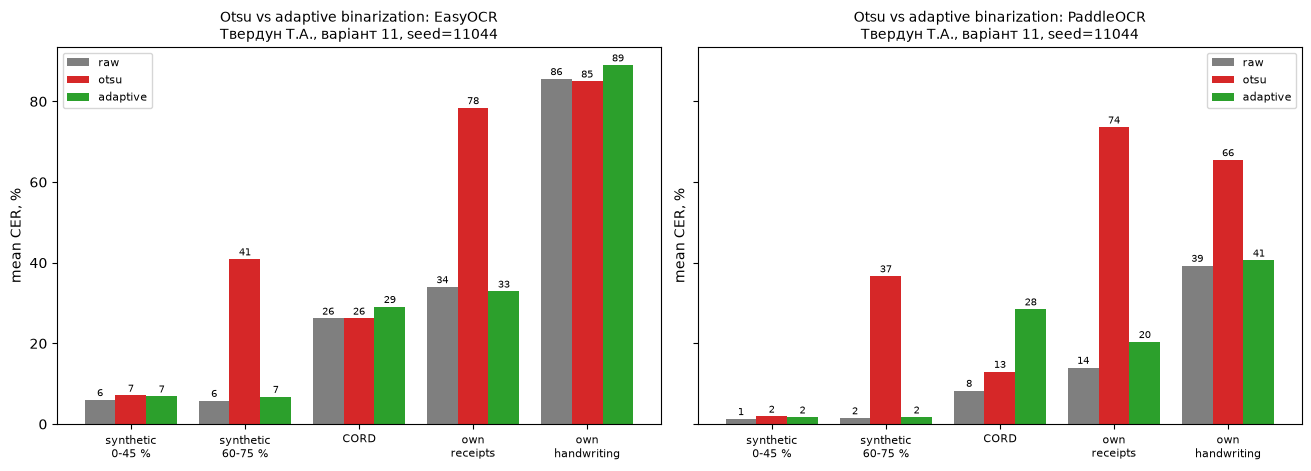

engine            EasyOCR                                PaddleOCR        \
prep                  raw  otsu adaptive otsu - adaptive       raw  otsu   
group                                                                      
synthetic 0-45 %      6.0   7.1      6.9             0.2       1.3   1.9   
synthetic 60-75 %     5.8  40.9      6.8            34.1       1.5  36.7   
CORD                 26.2  26.2     29.1            -2.8       8.3  13.0   
own receipts         34.0  78.4     32.9            45.6      14.0  73.6   
own handwriting      85.6  85.0     89.0            -3.9      39.3  65.5   

engine                                      
prep              adaptive otsu - adaptive  
group                                       
synthetic 0-45 %       1.7             0.1  
synthetic 60-75 %      1.7            35.0  
CORD                  28.5           -15.5  
own receipts          20.4            53.2  
own handwriting       40.6            24.9

In [49]:
GROUP_ORDER = ["synthetic 0-45 %", "synthetic 60-75 %", "CORD", "own receipts", "own handwriting"]
parts = [
    res.assign(group=np.where(res["level"] >= 60, "synthetic 60-75 %", "synthetic 0-45 %")),
    res_cord.assign(group="CORD"),
    res_own.assign(group=np.where(res_own["name"].str.startswith("receipt"), "own receipts", "own handwriting")),
]
feat_data = pd.concat([p[["group", "engine", "prep", "cer"]] for p in parts])
feat_data = feat_data[feat_data["prep"].isin(CURVE_PREPS)]
feat = (feat_data.pivot_table(index="group", columns=["engine", "prep"], values="cer") * 100).loc[GROUP_ORDER]
for eng in ENGINES:
    feat[(eng, "otsu - adaptive")] = feat[(eng, "otsu")] - feat[(eng, "adaptive")]
feat = feat[[(e, p) for e in ENGINES for p in CURVE_PREPS + ["otsu - adaptive"]]].round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True, layout="constrained")
x = np.arange(len(GROUP_ORDER))
for ax, eng in zip(axes, ENGINES):
    for k, prep in enumerate(CURVE_PREPS):
        bars = ax.bar(x + (k - 1) * 0.27, feat[(eng, prep)], width=0.27, color=COLORS[prep], label=prep)
        ax.bar_label(bars, fmt="%.0f", fontsize=7, padding=1)
    ax.set_xticks(x, [g.replace(" ", "\n", 1) for g in GROUP_ORDER], fontsize=8)
    ax.set_ylabel("mean CER, %")
    ax.legend(fontsize=8)
    stamp(ax, f"Otsu vs adaptive binarization: {eng}")
fig.savefig("figures/fig8_otsu_vs_adaptive.png", dpi=150, bbox_inches="tight")
plt.show()

feat

*Питання: опрацюйте особливість свого варіанта (адаптивна бінаризація проти Оцу) і підтвердіть висновок окремим графіком або таблицею.*

Таблиця і рисунок вище зводять CER без обробки, з Оцу і з адаптивною бінаризацією на всіх групах даних; стовпчик «otsu − adaptive» показує, на скільки в. п. адаптивна бінаризація краща за Оцу.

1. **Без тіні або зі слабкою тінню методи рівноцінні.** На синтетиці з затемненням 0–45 % різниця становить лише 0,1–0,2 в. п. (EasyOCR 7,1 і 6,9 %, PaddleOCR 1,9 і 1,7 %).
2. **При сильній нерівній освітленості адаптивна бінаризація значно краща.** На синтетиці 60–75 % Оцу дає 40,9 і 36,7 %, адаптивна — 6,8 і 1,7 % (виграш 34–35 в. п.). На власних чеках з різкою тінню від руки різниця ще більша: Оцу 78,4 і 73,6 %, адаптивна 32,9 і 20,4 % (виграш 46–53 в. п.). Причина: Оцу ставить один поріг на все зображення, і затінена частина фону потрапляє нижче порогу, а адаптивна бінаризація порівнює кожен піксель із його околом, тож плавна чи різка тінь змінює поріг разом із фоном.
3. **На малих вицвілих фрагментах адаптивна бінаризація шкодить.** На CORD (без вираженої тіні, висота фрагментів від 16 пікселів, матричний друк) адаптивна гірша за Оцу на 2,8 в. п. (EasyOCR) і на 15,5 в. п. (PaddleOCR: 28,5 % проти 13,0 %): локальний поріг із вікном 31 і зсувом 15 стирає бліді крапки, з яких складаються літери. Отже, параметри адаптивної бінаризації треба підбирати під розмір і контраст тексту.
4. **На рукописі** EasyOCR не працює за жодних умов (85–89 %), а для PaddleOCR адаптивна краща за Оцу на 24,9 в. п., бо одне з трьох фото зроблено з бічною тінню.

**Висновок щодо особливості варіанта.** Для документів із нерівним освітленням адаптивна бінаризація однозначно краща за глобальний Оцу, і цю перевагу підтверджено на синтетичних і на власних даних. Проте для нейромережевих інструментів жодна бінаризація не покращила результат відносно зображення без обробки: найкращий або близький до найкращого CER майже скрізь дає `raw` (PaddleOCR: 1,5 % на синтетиці з сильною тінню, 8,3 % на CORD, 14,0 % на чеках). Бінаризацію доцільно застосовувати лише тоді, коли вона потрібна з інших причин (класичний OCR, архівне зберігання), і тоді — адаптивну, з параметрами, підібраними під дані.

## 15. Аналіз п'яти найгірших зразків

Для різноманіття причин узято найгірший зразок (за CER будь-якого з інструментів) з кожної групи даних: синтетика без обробки, синтетика з Оцу, CORD, власні чеки, власний рукопис. Повні провали CORD детально розібрано у відповіді на питання 4.

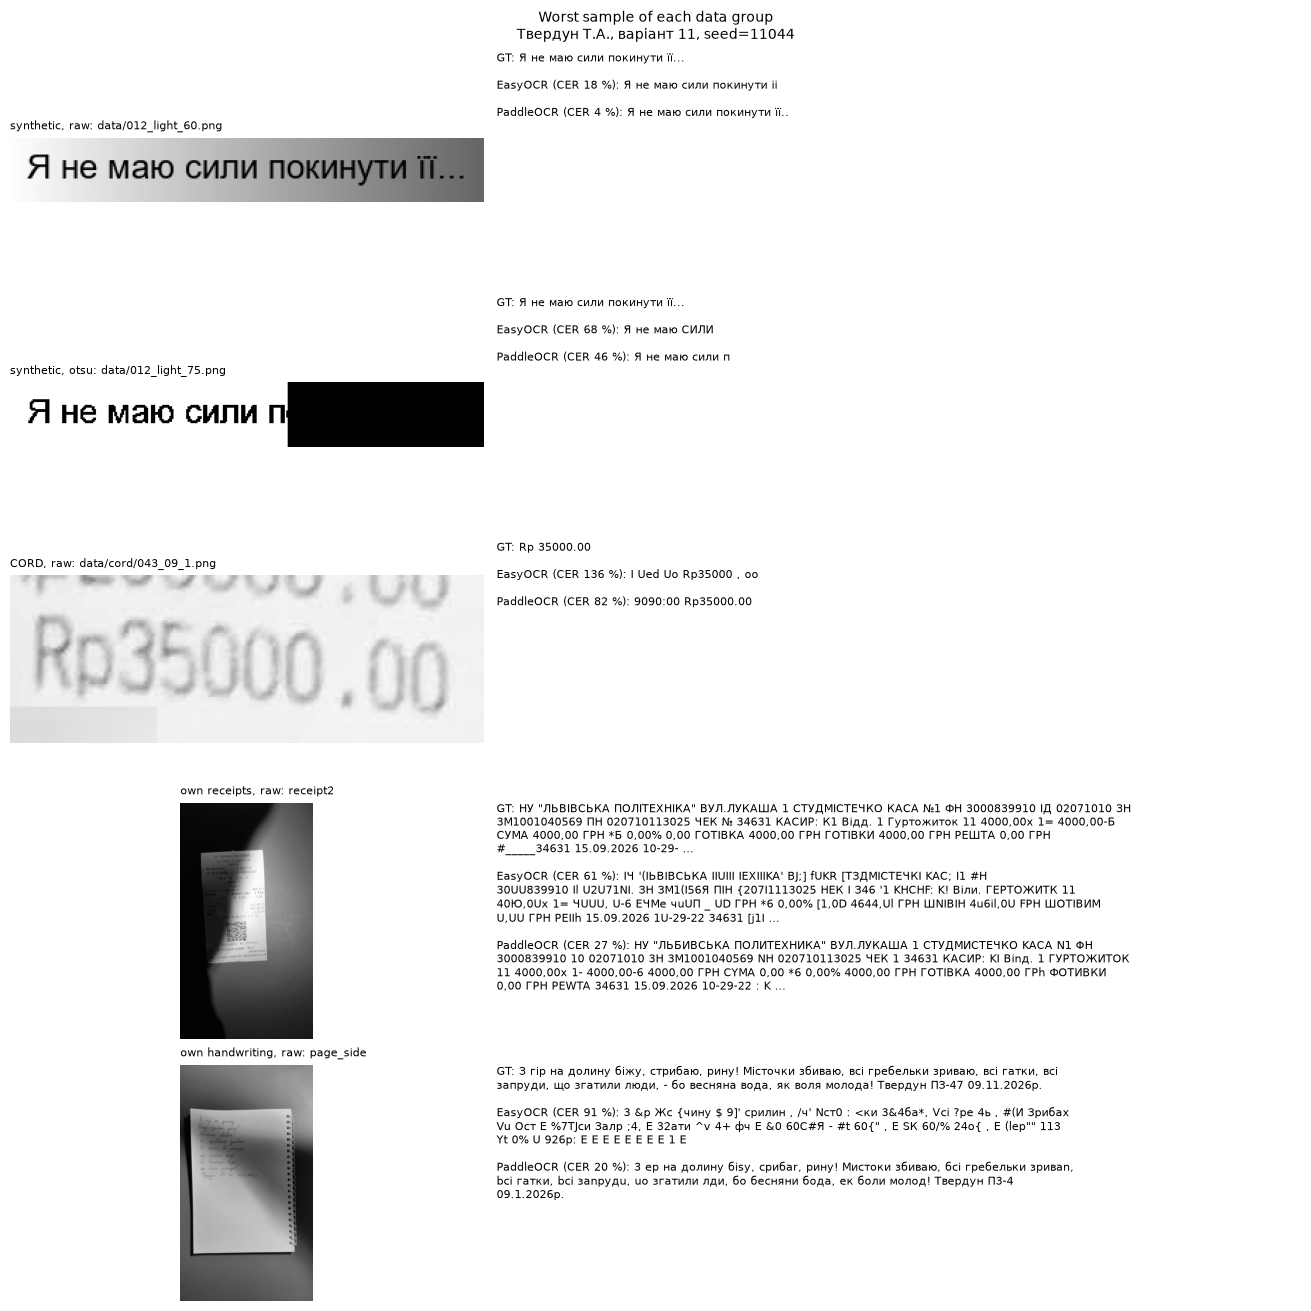

,group,sample,prep,"EasyOCR CER, %","PaddleOCR CER, %"
0,"synthetic, raw",data/012_light_60.png,raw,17.9,3.6
1,"synthetic, otsu",data/012_light_75.png,otsu,67.9,46.4
2,"CORD, raw",data/cord/043_09_1.png,raw,136.4,81.8
3,"own receipts, raw",receipt2,raw,60.7,27.4
4,"own handwriting, raw",page_side,raw,91.0,20.2


In [52]:
res["sample"] = [f"data/{i:03d}_{FACTOR}_{l}.png" for i, l in zip(res["id"], res["level"])]
res_cord["sample"] = [f"data/cord/{r:03d}_{l:02d}_{s}.png"
                      for r, l, s in zip(res_cord["receipt"], res_cord["line"], res_cord["seg"])]
res_own["sample"] = res_own["name"]

def load_sample(sample, prep):
    img = own_imgs[sample] if sample in own_imgs else cv2.imread(sample, cv2.IMREAD_GRAYSCALE)
    return preprocess(img, PREP[prep])

GROUPS5 = {
    "synthetic, raw": res[res["prep"] == "raw"],
    "synthetic, otsu": res[res["prep"] == "otsu"],
    "CORD, raw": res_cord[res_cord["prep"] == "raw"],
    "own receipts, raw": res_own[(res_own["prep"] == "raw") & res_own["name"].str.startswith("receipt")],
    "own handwriting, raw": res_own[(res_own["prep"] == "raw") & res_own["name"].str.startswith("page")],
}
worst5 = []
for group, d in GROUPS5.items():
    w = d.loc[d["cer"].idxmax()]
    both = d[d["sample"] == w["sample"]].set_index("engine")
    row = {"group": group, "sample": w["sample"], "prep": w["prep"], "gt": w["gt"]}
    for e in ENGINES:
        row[f"{e} CER, %"] = both.loc[e, "cer"] * 100
        row[f"{e} pred"] = both.loc[e, "pred"]
    worst5.append(row)
worst5 = pd.DataFrame(worst5)

def short(s, n=300):
    s = normalize(s)
    return s if len(s) <= n else s[:n] + " …"

fig, axes = plt.subplots(len(worst5), 2, figsize=(13, 2.6 * len(worst5)),
                         gridspec_kw={"width_ratios": [1, 1.7]}, layout="constrained")
for (ax_img, ax_txt), w in zip(axes, worst5.to_dict("records")):
    ax_img.imshow(load_sample(w["sample"], w["prep"]), cmap="gray", vmin=0, vmax=255)
    ax_img.set_title(f"{w['group']}: {w['sample']}", fontsize=8, loc="left")
    ax_img.axis("off")
    parts = [f"GT: {short(w['gt'])}"]
    parts += [f"{e} (CER {w[f'{e} CER, %']:.0f} %): {short(w[f'{e} pred'])}" for e in ENGINES]
    ax_txt.text(0, 1, "\n\n".join(textwrap.fill(p, 95) for p in parts), va="top", fontsize=8)
    ax_txt.axis("off")
fig.suptitle(f"Worst sample of each data group\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig9_worst5.png", dpi=150, bbox_inches="tight")
plt.show()

worst5.drop(columns=["gt", "EasyOCR pred", "PaddleOCR pred"]).round(1)

**1. Синтетика без обробки — рядок «Я не маю сили покинути її...» (тінь 60 %).** EasyOCR (17,9 %): «…покинути ii» — обидві «ї» замінено латинськими «i» без крапок, а три крапки втрачено. *Категорія: заміна символів (гомогліфи) і втрата розділових знаків.* PaddleOCR (3,6 %) лише втратив одну крапку з трьох. Тінь тут ні до чого: це систематичні помилки EasyOCR, видимі й на рис. 13.5.

**2. Синтетика з Оцу — той самий рядок при тіні 75 %.** Оцу залив праву частину рядка чорним, і обидва інструменти прочитали лише початок: EasyOCR «Я не маю СИЛИ» (67,9 %), PaddleOCR «Я не маю сили п» (46,4 %). *Категорія: детекція* — тексту в чорній ділянці фізично немає, його не можна відновити жодною постобробкою; причина в попередній обробці, а не в інструментах.

**3. CORD — фрагмент «Rp 35000.00».** У вирізку потрапила нижня частина сусіднього рядка вище, і обидва інструменти її прочитали: EasyOCR «I Ued Uo Rp35000 , oo» (136,4 %), PaddleOCR «9090:00 Rp35000.00» (81,8 %). CER більший за 100 %, бо зайвих символів вставлено більше, ніж є в еталоні. *Категорія: сегментація* (помилка вирізання рядка, тобто етапу до розпізнавання). Сам рядок PaddleOCR прочитав правильно.

**4. Власний чек Політехніки з тінню від руки.** EasyOCR (60,7 %) у дрібному касовому шрифті й тіні замінює більшість кириличних літер латинськими та сміттєвими символами («IIUIII IEXIIIKA» замість «ПОЛІТЕХНІКА»). *Категорія: заміна символів.* PaddleOCR (27,4 %) читає текст, але систематично пише «и» замість «і» («ЛЬБИВСЬКА ПОЛИТЕХНИКА», «СТУДМИСТЕЧКО», «ФИСКАЛЬНИЙ»), тобто «осучаснює» текст до російського правопису, а також ставить латинські й навіть грецькі двійники («KACA», «CYMA», «ΦH»). *Категорія: мовна «корекція» і гомогліфи.* Крім того, у рядках із двома стовпцями (назва ліворуч, сума праворуч, трохи вище) порушено порядок слів («4000,00 ГPH CYMA»).

**5. Власний рукопис, бічне світло з тінню.** EasyOCR (91,0 %) рукопис не читає: замість слів — набір символів, а спіраль зошита розпізнано як текст («E E E E E …»). *Категорія: галюцинація* (текст, якого немає на зображенні) і невідповідність домену (рукопис замість друку). PaddleOCR (20,2 %) розпізнав більшість слів, але плутає рукописні літери («весняна вода» → «бесняни бода», «всі» → «bci» з латинськими літерами). *Категорія: заміна символів.*

**Висновок.** Найгірші результати мають різні причини: на етапі попередньої обробки (Оцу, зразок 2) і сегментації (зразок 3) виникають помилки, які наступні етапи не можуть виправити; заміни й гомогліфи (зразки 1, 4, 5) частково виправляються постобробкою (питання 8); мовна «корекція» PaddleOCR («і» → «и») потребує словникової перевірки; галюцинації EasyOCR на рукописі показують, що для рукописного тексту потрібен інший тип моделі.

## 16. Структурування результату (JSON)

### 16.1. Вилучення дати й суми з чеків

In [54]:
KEY_LAT2CYR = str.maketrans("aceiopxyABCEHIKMOPTXY", "асеіорхуАВСЕНІКМОРТХУ")
DATE_RE = re.compile(r"\b(\d{2})[./](\d{2})[./](\d{4}|\d{2})\b")
NUMBER = r"(?:\d{1,3}(?: \d{3})+|\d+)(?:[.,]\d{2})?"
AMOUNT_RE = re.compile(r"(?:ДО СПЛАТИ|СУМА|РАЗОМ)\D{0,15}?(" + NUMBER + ")", re.IGNORECASE)

def to_float(s):
    return float(s.replace(" ", "").replace(",", "."))

def extract_fields(text):
    t = normalize(text).translate(KEY_LAT2CYR)
    fields = {"date": None, "amount": None}
    m = DATE_RE.search(t)
    if m:
        d, mth, y = int(m.group(1)), int(m.group(2)), int(m.group(3))
        y = y + 2000 if y < 100 else y
        try:
            fields["date"] = datetime.date(y, mth, d).isoformat()
        except ValueError:
            pass
    m = AMOUNT_RE.search(t)
    if m:
        fields["amount"] = to_float(m.group(1))
    return fields

def validate(fields, text):
    t = normalize(text).translate(KEY_LAT2CYR)
    problems = []
    if fields["date"] is None:
        problems.append("date not found")
    elif not (datetime.date(2000, 1, 1) <= datetime.date.fromisoformat(fields["date"]) <= datetime.date.today()):
        problems.append("date out of range")
    if fields["amount"] is None:
        problems.append("amount not found")
    elif not (0 < fields["amount"] < 1_000_000):
        problems.append("amount out of range")
    elif sum(abs(to_float(n) - fields["amount"]) < 0.005 for n in re.findall(NUMBER, t)) < 2:
        problems.append("amount not confirmed by other numbers")
    return problems

rows = []
for name, gt_text in zip(own["name"], own["gt"]):
    if not name.startswith("receipt"):
        continue
    f = extract_fields(gt_text)
    rows.append({"name": name, "source": "transcription", **f, "problems": "; ".join(validate(f, gt_text))})
    for eng in ENGINES:
        pred = res_own[(res_own["name"] == name) & (res_own["engine"] == eng) & (res_own["prep"] == "raw")]["pred"].iloc[0]
        f = extract_fields(pred)
        rows.append({"name": name, "source": eng, **f, "problems": "; ".join(validate(f, pred))})
fields_table = pd.DataFrame(rows)
fields_table

,name,source,date,amount,problems
0,receipt1,transcription,2026-06-30,1649.0,
1,receipt1,EasyOCR,NaN,649.0,date not found
2,receipt1,PaddleOCR,2026-06-30,1649.0,
3,receipt2,transcription,2026-09-15,4000.0,
4,receipt2,EasyOCR,2026-09-15,NaN,amount not found
5,receipt2,PaddleOCR,2026-09-15,0.0,amount out of range
6,receipt3,transcription,2026-05-04,1550.0,
7,receipt3,EasyOCR,NaN,1.0,date not found
8,receipt3,PaddleOCR,2026-05-04,1550.0,


### 16.2. JSON з результатами і метаданими

In [55]:
conf_raw = res_own[res_own["prep"] == "raw"]
gt_fields = {n: extract_fields(g) for n, g in zip(own["name"], own["gt"])}
records = []
for r in conf_raw.itertuples():
    path = OWN[r.name]
    with open(path, "rb") as f:
        image_sha = hashlib.sha256(f.read()).hexdigest()
    info = own[own["name"] == r.name].iloc[0]
    rec = {
        "file": info["file"],
        "image_sha256": image_sha,
        "exif": {"taken": info["taken"], "camera": info["camera"]},
        "engine": r.engine,
        "engine_version": version("easyocr") if r.engine == "EasyOCR" else version("paddleocr"),
        "params": ({"languages": ["uk", "en"]} if r.engine == "EasyOCR" else
                   {"det_model": "PP-OCRv5_mobile_det", "rec_model": PADDLE_REC["uk"], "enable_mkldnn": False}),
        "preprocessing": {"config": r.prep, "max_side": 2000, "rotate180": r.name in ROTATE_180},
        "text": normalize(r.pred),
        "confidence": round(float(r.conf), 3),
        "time_sec": round(float(r.sec), 2),
        "cer": round(float(r.cer), 3),
    }
    if r.name.startswith("receipt"):
        fields = extract_fields(r.pred)
        problems = validate(fields, r.pred)
        rec["fields"] = fields
        rec["fields_correct"] = {k: fields[k] == gt_fields[r.name][k] for k in fields}
        rec["problems"] = problems
        rec["needs_review"] = bool(problems) or rec["confidence"] < 0.88
    records.append(rec)

with open("data/own_results.json", "w", encoding="utf-8") as f:
    json.dump(records, f, ensure_ascii=False, indent=2)

acc = pd.DataFrame([{"engine": r["engine"], **r["fields_correct"]} for r in records if "fields" in r])
print("Field accuracy (share of correct fields):")
print(acc.groupby("engine")[["date", "amount"]].mean().round(2))
print(json.dumps(records[-1], ensure_ascii=False, indent=2))

Field accuracy (share of correct fields):
           date  amount
engine                 
EasyOCR    0.33    0.00
PaddleOCR  1.00    0.67
{
  "file": "receipt3.jpg",
  "image_sha256": "614f44a648e3d707b57db6e440d9861398f8351034dcb75a165644ea6307eb1f",
  "exif": {
    "taken": "2026:11:09 19:13:06",
    "camera": "Galaxy A36 5G"
  },
  "engine": "PaddleOCR",
  "engine_version": "3.4.1",
  "params": {
    "det_model": "PP-OCRv5_mobile_det",
    "rec_model": "eslav_PP-OCRv5_mobile_rec",
    "enable_mkldnn": false
  },
  "preprocessing": {
    "config": "raw",
    "max_side": 2000,
    "rotate180": false
  },
  "text": "CHECKBOX ТОВАРИСТВО З ОБМЕЖЕНОЮ ВИДПОВІДАЛЬНТСТЮ \"ЮНТТ КРАФТ Магазин Haгvest Львивська область, м. Львів, Франківський район, вул. кульпарківська, буд.226-A PH 452243117166 1.000 × 1550.00 Гаманець Трифолд міні шкиряний ментол 1550.00 A Безготівкова 1550.00 ГPH Картка CYMA 1550.00 ГPH ПДВ А 20.00% 258.33 чек № CwQTеeMskеm 04.05.2026 19-51-09 ОНЛАЙН ФН ПРРО 4001360831 ФТСКА

**Висновок.** Шаблони дати й суми правильно спрацювали на всіх трьох ручних транскрипціях (3/3 дати і 3/3 суми), тобто самі правила коректні. На результатах PaddleOCR без обробки точність полів становить 1,00 для дати і 0,67 для суми, на результатах EasyOCR — 0,33 і 0,00. Помилки вилучення спричинені помилками розпізнавання:
- **гомогліфи**: PaddleOCR записав «СУМА» латинськими літерами («CYMA»), тому перед пошуком ключових слів латинські двійники замінюються кириличними; без цього суму не знайдено б на жодному чеку з таким написанням;
- **порядок читання**: на чеку Політехніки сума «4000,00» надрукована трохи вище за підпис «СУМА», тож після підпису OCR поставив «0,00»; перевірка діапазону (сума > 0) відхилила це значення;
- **спотворені цифри** в EasyOCR: дату не знайдено на двох чеках, а суми прочитано неправильно (649 замість 1649, 1 замість 1550).

Правила перевірки разом із порогом впевненості 0,88 (питання 5) позначили `needs_review` для всіх записів із помилковими полями — жодного неправильного запису не прийнято автоматично. Автоматично прийнято лише чек Harvest (PaddleOCR, впевненість 0,90, обидва поля правильні). Чек MTA.UA PaddleOCR прочитав правильно, але через впевненість 0,862 < 0,88 його теж направлено на перевірку — це ціна обережного порогу.

Кожен запис JSON містить хеш SHA-256 оригінального файлу, EXIF (дата зйомки, модель камери), версію інструмента, моделі, параметри попередньої обробки, текст, впевненість, час і CER, що забезпечує відтворюваність і простежуваність походження даних (data lineage). Файл `data/own_results.json` генерується кодом і в репозиторії не зберігається.